In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ahmedamir7/cpp-satd/cppsatd.csv
/kaggle/input/datasets/ahmedamir7/comment-satd/comment.csv


In [15]:
# Kaggle already provides NumPy, pandas, scikit-learn, and Matplotlib.
# Install only the Hugging Face packages needed for this project.

%pip install -q transformers datasets accelerate 


Note: you may need to restart the kernel to use updated packages.


In [16]:
import os
import gc
import json
import random
import inspect
import warnings
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

from datasets import Dataset, DatasetDict

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    precision_recall_curve,
    average_precision_score,
)

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import transformers
import datasets
import accelerate

from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

warnings.filterwarnings("ignore")

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)

NumPy: 2.1.3
pandas: 2.3.3
PyTorch: 2.11.0+cu130
scikit-learn: 1.6.1
Transformers: 5.20.2
Datasets: 4.8.5
Accelerate: 1.15.0


In [17]:
# ================================================================
# DATA
# ================================================================

# Example:
# /kaggle/input/cppsatd-dataset/cppsatd.csv
CSV_PATH = "/kaggle/input/datasets/ahmedamir7/cpp-satd/cppsatd.csv"

# Change these after inspecting the columns in Cell 5.
TEXT_COLUMN = "commenttext"
LABEL_COLUMN = "annotation"

# Optional repository/project column.
# Use None if the dataset does not provide one.
GROUP_COLUMN = None


# ================================================================
# MODEL
# ================================================================

MODEL_NAME = "microsoft/codebert-base"
MAX_LENGTH = 256

OUTPUT_DIR = "/kaggle/working/codebert_cppsatd_multiclass"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)


# ================================================================
# REPRODUCIBILITY
# ================================================================

SEED = 42


# ================================================================
# DATA SPLIT
# ================================================================

TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

# Recommended initial experiment:
# False = stratified random split.
#
# Stronger cross-project experiment:
# True = repository-aware split.
USE_GROUP_SPLIT = False


# ================================================================
# TRAINING
# ================================================================

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5

# Safe starting values for a Kaggle T4 or P100 at length 256.
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 2

WARMUP_RATIO = 0.10
LOGGING_STEPS = 200

EARLY_STOPPING_PATIENCE = 2


# ================================================================
# CLASS IMBALANCE
# ================================================================

# Options:
# "sqrt"      = recommended first experiment
# "balanced"  = stronger inverse-frequency correction
# "effective" = effective-number weighting
WEIGHT_STRATEGY = "sqrt"

MIN_CLASS_WEIGHT = 0.25
MAX_CLASS_WEIGHT = 10.0

# Options:
# "weighted_ce"
# "weighted_focal"
LOSS_TYPE = "weighted_ce"

FOCAL_GAMMA = 2.0


# ================================================================
# MEMORY AND SPEED
# ================================================================

# Enable gradient checkpointing if GPU memory is limited.
# Training becomes slower but consumes less memory.
USE_GRADIENT_CHECKPOINTING = False

# Use a limited number of records only for pipeline testing.
# Set to None for the complete experiment.
DEBUG_SAMPLE_SIZE = None


print("Configuration loaded.")
print("Model:", MODEL_NAME)
print("Maximum length:", MAX_LENGTH)
print("Output directory:", OUTPUT_DIR)

Configuration loaded.
Model: microsoft/codebert-base
Maximum length: 256
Output directory: /kaggle/working/codebert_cppsatd_multiclass


In [18]:
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"CSV_PATH does not exist:\n{CSV_PATH}\n\n"
        "Copy the correct path from the output of Cell 5 "
        "and update Cell 4."
    )

df = pd.read_csv(
    CSV_PATH,
    low_memory=False,
)

print("Original dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nColumn data types:")
display(df.dtypes.to_frame("data_type"))

Original dataset shape: (531367, 7)

Available columns:
['comment_id', 'commenttext', 'preceding_code', 'succeeding_code', 'file_id', 'projectname', 'annotation']

First five records:


,comment_id,commenttext,preceding_code,succeeding_code,file_id,projectname,annotation
0,0,// Copyright (c) 2014-2021 The Bitcoin Core de...,NaN,NaN,1.cpp,bitcoin,NON-SATD
1,1,// NaN is not guaranteed to round-trip exactly.,uint64_t TestDouble(double f) {\n uint64_t ...,\n BOOST_CHECK(std::isnan(f2));\n } ...,1.cpp,bitcoin,NON-SATD
2,2,// Everything else is.,BOOST_CHECK(std::isnan(f2));\n } el...,\n BOOST_CHECK(!std::isnan(f2));\n ...,1.cpp,bitcoin,NON-SATD
3,3,// namespace,},NaN,1.cpp,bitcoin,NON-SATD
4,4,// Test specific values against their expected...,BOOST_AUTO_TEST_CASE(double_serfloat_tests) {\...,"\n BOOST_CHECK_EQUAL(TestDouble(0.0), 0U);\...",1.cpp,bitcoin,NON-SATD



Column data types:


,data_type
comment_id,int64
commenttext,object
preceding_code,object
succeeding_code,object
file_id,object
projectname,object
annotation,object


In [19]:
required_columns = {
    TEXT_COLUMN,
    LABEL_COLUMN,
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"The following configured columns were not found: "
        f"{missing_columns}\n\n"
        f"Available columns:\n{df.columns.tolist()}"
    )

if GROUP_COLUMN is not None and GROUP_COLUMN not in df.columns:
    print(
        f"Warning: GROUP_COLUMN '{GROUP_COLUMN}' was not found. "
        "GROUP_COLUMN has been changed to None."
    )
    GROUP_COLUMN = None

print("Text column:", TEXT_COLUMN)
print("Label column:", LABEL_COLUMN)
print("Group column:", GROUP_COLUMN)

Text column: commenttext
Label column: annotation
Group column: None


In [20]:
columns_to_keep = [
    TEXT_COLUMN,
    LABEL_COLUMN,
]

if GROUP_COLUMN is not None:
    columns_to_keep.append(GROUP_COLUMN)

df = df[columns_to_keep].copy()

original_size = len(df)

# Remove missing text or labels.
df = df.dropna(
    subset=[
        TEXT_COLUMN,
        LABEL_COLUMN,
    ]
).copy()

# Normalize whitespace without changing code-related punctuation.
df[TEXT_COLUMN] = (
    df[TEXT_COLUMN]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df[LABEL_COLUMN] = (
    df[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

# Remove empty comments.
df = df[
    df[TEXT_COLUMN].str.len() > 0
].copy()

# Remove exact duplicated comment-label pairs.
df = df.drop_duplicates(
    subset=[
        TEXT_COLUMN,
        LABEL_COLUMN,
    ],
    keep="first",
).reset_index(drop=True)

if DEBUG_SAMPLE_SIZE is not None:
    if DEBUG_SAMPLE_SIZE < len(df):
        df, _ = train_test_split(
            df,
            train_size=DEBUG_SAMPLE_SIZE,
            random_state=SEED,
            stratify=df[LABEL_COLUMN],
        )

        df = df.reset_index(drop=True)

print("Original records:", original_size)
print("Records after cleaning:", len(df))
print("Removed records:", original_size - len(df))

Original records: 531367
Records after cleaning: 348994
Removed records: 182373


In [21]:
raw_label_distribution = (
    df[LABEL_COLUMN]
    .value_counts(dropna=False)
    .rename_axis("raw_label")
    .reset_index(name="count")
)

raw_label_distribution["percentage"] = (
    raw_label_distribution["count"]
    / raw_label_distribution["count"].sum()
    * 100
).round(5)

print("Number of raw labels:", len(raw_label_distribution))

display(raw_label_distribution)

Number of raw labels: 6


,raw_label,count,percentage
0,NON-SATD,337705,96.76527
1,DESIGN/CODE,7216,2.06766
2,REQUIREMENT,3317,0.95045
3,DEFECT,376,0.10774
4,TEST,338,0.09685
5,DOCUMENTATION,42,0.01203


In [22]:
LABEL_ALIASES = {
    # NON-SATD
    "non-satd": "NON-SATD",
    "non satd": "NON-SATD",
    "nonsatd": "NON-SATD",
    "non_satd": "NON-SATD",
    "no satd": "NON-SATD",
    "not satd": "NON-SATD",
    "none": "NON-SATD",
    "non technical debt": "NON-SATD",

    # Design/Code Debt
    "design/code debt": "DESIGN/CODE DEBT",
    "design code debt": "DESIGN/CODE DEBT",
    "design debt": "DESIGN/CODE DEBT",
    "code debt": "DESIGN/CODE DEBT",
    "design/code": "DESIGN/CODE DEBT",
    "design_debt": "DESIGN/CODE DEBT",
    "code_debt": "DESIGN/CODE DEBT",

    # Requirement Debt
    "requirement debt": "REQUIREMENT DEBT",
    "requirements debt": "REQUIREMENT DEBT",
    "requirement_debt": "REQUIREMENT DEBT",

    # Defect Debt
    "defect debt": "DEFECT DEBT",
    "defect_debt": "DEFECT DEBT",
    "bug debt": "DEFECT DEBT",

    # Test Debt
    "test debt": "TEST DEBT",
    "testing debt": "TEST DEBT",
    "test_debt": "TEST DEBT",

    # Documentation Debt
    "documentation debt": "DOCUMENTATION DEBT",
    "documentation_debt": "DOCUMENTATION DEBT",
    "document debt": "DOCUMENTATION DEBT",
}


def standardize_label(raw_label):
    original_label = str(raw_label).strip()
    normalized_label = original_label.lower()

    return LABEL_ALIASES.get(
        normalized_label,
        original_label,
    )


df[LABEL_COLUMN] = df[LABEL_COLUMN].apply(
    standardize_label
)

standardized_distribution = (
    df[LABEL_COLUMN]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="count")
)

standardized_distribution["percentage"] = (
    standardized_distribution["count"]
    / standardized_distribution["count"].sum()
    * 100
).round(5)

display(standardized_distribution)

,label,count,percentage
0,NON-SATD,337705,96.76527
1,DESIGN/CODE DEBT,7216,2.06766
2,REQUIREMENT,3317,0.95045
3,DEFECT,376,0.10774
4,TEST,338,0.09685
5,DOCUMENTATION,42,0.01203


In [23]:
EXPECTED_LABELS = {
    "NON-SATD",
    "DESIGN/CODE DEBT",
    "REQUIREMENT",
    "DEFECT",
    "TEST",
    "DOCUMENTATION",
}

detected_labels = set(
    df[LABEL_COLUMN].unique()
)

unexpected_labels = detected_labels.difference(
    EXPECTED_LABELS
)

missing_labels = EXPECTED_LABELS.difference(
    detected_labels
)

print("Detected labels:")

for label in sorted(detected_labels):
    print("-", label)

if unexpected_labels:
    raise ValueError(
        "Unexpected labels were found:\n"
        f"{sorted(unexpected_labels)}\n\n"
        "Add their exact raw spellings to LABEL_ALIASES "
        "in Cell 10, then rerun from Cell 10."
    )

if missing_labels:
    raise ValueError(
        "Expected labels are missing:\n"
        f"{sorted(missing_labels)}\n\n"
        "Check whether the dataset uses different spellings."
    )

print("\nAll six expected labels were detected.")

Detected labels:
- DEFECT
- DESIGN/CODE DEBT
- DOCUMENTATION
- NON-SATD
- REQUIREMENT
- TEST

All six expected labels were detected.


,count,percentage,ratio_to_smallest
annotation,,,
NON-SATD,337705,96.76527,8040.60
DESIGN/CODE DEBT,7216,2.06766,171.81
REQUIREMENT,3317,0.95045,78.98
DEFECT,376,0.10774,8.95
TEST,338,0.09685,8.05
DOCUMENTATION,42,0.01203,1.00


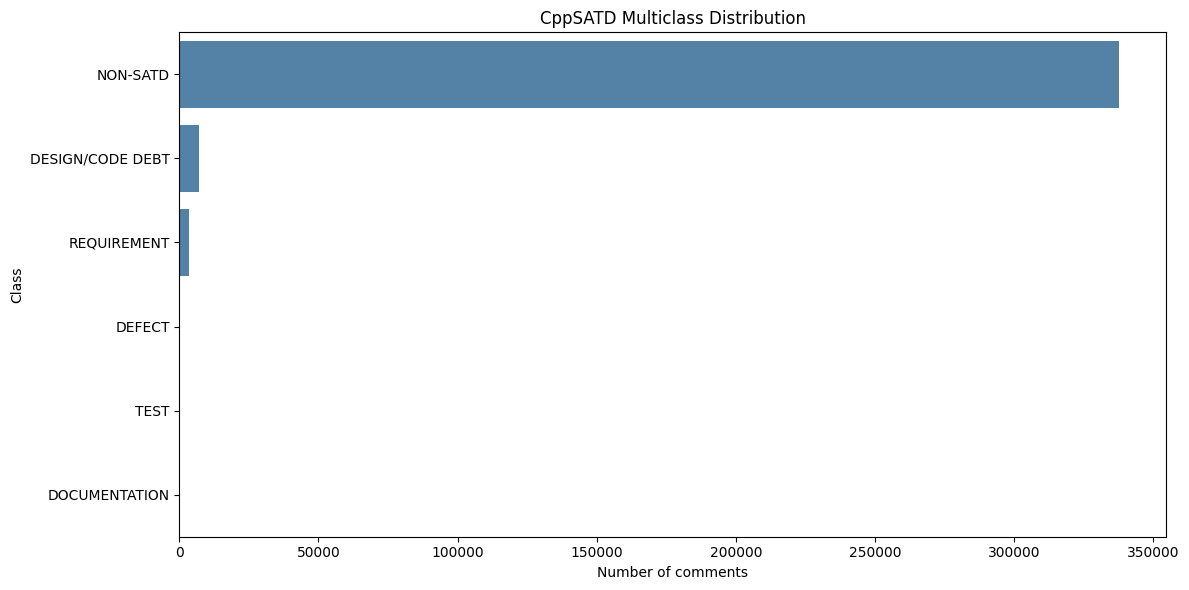

In [24]:
class_counts = (
    df[LABEL_COLUMN]
    .value_counts()
    .sort_values(ascending=False)
)

distribution_table = pd.DataFrame({
    "count": class_counts,
    "percentage": (
        class_counts / len(df) * 100
    ).round(5),
    "ratio_to_smallest": (
        class_counts / class_counts.min()
    ).round(2),
})

display(distribution_table)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=class_counts.values,
    y=class_counts.index,
    color="steelblue",
)

plt.title("CppSATD Multiclass Distribution")
plt.xlabel("Number of comments")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

In [25]:
LABEL_ORDER = [
    "NON-SATD",
    "DESIGN/CODE DEBT",
    "REQUIREMENT",
    "DEFECT",
    "TEST",
    "DOCUMENTATION",
]

label2id = {
    label: index
    for index, label in enumerate(LABEL_ORDER)
}

id2label = {
    index: label
    for label, index in label2id.items()
}

NUM_LABELS = len(LABEL_ORDER)

df["label_id"] = (
    df[LABEL_COLUMN]
    .map(label2id)
    .astype(int)
)

label_mapping_df = pd.DataFrame({
    "label_id": list(id2label.keys()),
    "label": list(id2label.values()),
})

display(label_mapping_df)

with open(
    os.path.join(OUTPUT_DIR, "label_mapping.json"),
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "label2id": label2id,
            "id2label": {
                str(key): value
                for key, value in id2label.items()
            },
        },
        file,
        indent=2,
        ensure_ascii=False,
    )

,label_id,label
0,0,NON-SATD
1,1,DESIGN/CODE DEBT
2,2,REQUIREMENT
3,3,DEFECT
4,4,TEST
5,5,DOCUMENTATION


In [26]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    set_seed(seed)


seed_everything(SEED)

print("Random seed:", SEED)

Random seed: 42


In [27]:
def create_stratified_split(dataframe):
    train_validation_df, test_df = train_test_split(
        dataframe,
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=dataframe["label_id"],
    )

    relative_validation_size = (
        VALIDATION_SIZE / (1.0 - TEST_SIZE)
    )

    train_df, validation_df = train_test_split(
        train_validation_df,
        test_size=relative_validation_size,
        random_state=SEED,
        stratify=train_validation_df["label_id"],
    )

    return train_df, validation_df, test_df


def create_repository_split(dataframe):
    if GROUP_COLUMN is None:
        raise ValueError(
            "GROUP_COLUMN must be configured before using "
            "repository-aware splitting."
        )

    available_groups = (
        dataframe[GROUP_COLUMN]
        .dropna()
        .unique()
        .tolist()
    )

    if len(available_groups) < 3:
        raise ValueError(
            "At least three repositories are required for "
            "repository-aware splitting."
        )

    rng = np.random.default_rng(SEED)
    rng.shuffle(available_groups)

    number_of_groups = len(available_groups)

    number_of_test_groups = max(
        1,
        round(number_of_groups * TEST_SIZE),
    )

    number_of_validation_groups = max(
        1,
        round(number_of_groups * VALIDATION_SIZE),
    )

    if (
        number_of_test_groups
        + number_of_validation_groups
        >= number_of_groups
    ):
        number_of_test_groups = 1
        number_of_validation_groups = 1

    test_groups = set(
        available_groups[:number_of_test_groups]
    )

    validation_groups = set(
        available_groups[
            number_of_test_groups:
            number_of_test_groups
            + number_of_validation_groups
        ]
    )

    train_groups = set(available_groups).difference(
        test_groups,
        validation_groups,
    )

    train_df = dataframe[
        dataframe[GROUP_COLUMN].isin(train_groups)
    ].copy()

    validation_df = dataframe[
        dataframe[GROUP_COLUMN].isin(validation_groups)
    ].copy()

    test_df = dataframe[
        dataframe[GROUP_COLUMN].isin(test_groups)
    ].copy()

    print("Training repositories:", sorted(train_groups))
    print("Validation repositories:", sorted(validation_groups))
    print("Test repositories:", sorted(test_groups))

    return train_df, validation_df, test_df

In [28]:
minimum_class_count = (
    df[LABEL_COLUMN]
    .value_counts()
    .min()
)

if minimum_class_count < 3:
    raise ValueError(
        "At least one class has fewer than three examples. "
        "A three-way stratified split is not possible."
    )

if USE_GROUP_SPLIT:
    train_df, validation_df, test_df = (
        create_repository_split(df)
    )
else:
    train_df, validation_df, test_df = (
        create_stratified_split(df)
    )

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training size:", len(train_df))
print("Validation size:", len(validation_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(validation_df) + len(test_df))

Training size: 244295
Validation size: 52349
Test size: 52350
Total: 348994


In [29]:
def split_distribution(split_name, split_dataframe):
    counts = (
        split_dataframe[LABEL_COLUMN]
        .value_counts()
        .reindex(LABEL_ORDER, fill_value=0)
    )

    percentages = (
        counts / len(split_dataframe) * 100
    ).round(5)

    return pd.DataFrame({
        "split": split_name,
        "label": LABEL_ORDER,
        "count": counts.values,
        "percentage": percentages.values,
    })


all_split_distributions = pd.concat(
    [
        split_distribution("train", train_df),
        split_distribution("validation", validation_df),
        split_distribution("test", test_df),
    ],
    ignore_index=True,
)

display(all_split_distributions)

missing_from_training = set(
    range(NUM_LABELS)
).difference(
    train_df["label_id"].unique()
)

if missing_from_training:
    missing_names = [
        id2label[class_id]
        for class_id in sorted(missing_from_training)
    ]

    raise ValueError(
        f"Classes missing from training: {missing_names}"
    )

,split,label,count,percentage
0,train,NON-SATD,236392,96.76498
1,train,DESIGN/CODE DEBT,5051,2.06758
2,train,REQUIREMENT,2322,0.95049
3,train,DEFECT,264,0.10807
4,train,TEST,236,0.09660
5,train,DOCUMENTATION,30,0.01228
6,validation,NON-SATD,50656,96.76594
7,validation,DESIGN/CODE DEBT,1083,2.06881
8,validation,REQUIREMENT,497,0.94940
9,validation,DEFECT,56,0.10697


In [30]:
def calculate_class_weights(
    labels,
    num_labels,
    strategy="sqrt",
    beta=0.9999,
):
    labels = np.asarray(labels)

    class_ids = np.arange(num_labels)

    counts = np.bincount(
        labels,
        minlength=num_labels,
    ).astype(np.float64)

    if np.any(counts == 0):
        raise ValueError(
            f"A training class has zero examples: {counts}"
        )

    if strategy == "balanced":
        weights = compute_class_weight(
            class_weight="balanced",
            classes=class_ids,
            y=labels,
        )

    elif strategy == "sqrt":
        balanced_weights = compute_class_weight(
            class_weight="balanced",
            classes=class_ids,
            y=labels,
        )

        weights = np.sqrt(balanced_weights)

    elif strategy == "effective":
        effective_numbers = (
            1.0 - np.power(beta, counts)
        )

        weights = (
            (1.0 - beta) / effective_numbers
        )

    else:
        raise ValueError(
            "WEIGHT_STRATEGY must be 'sqrt', "
            "'balanced', or 'effective'."
        )

    # Stabilize the overall loss scale.
    weights = weights / weights.mean()

    # Protect against unstable gradients from extremely rare classes.
    weights = np.clip(
        weights,
        MIN_CLASS_WEIGHT,
        MAX_CLASS_WEIGHT,
    )

    return (
        weights.astype(np.float32),
        counts.astype(int),
    )


class_weights_np, training_class_counts = (
    calculate_class_weights(
        labels=train_df["label_id"].values,
        num_labels=NUM_LABELS,
        strategy=WEIGHT_STRATEGY,
    )
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
)

class_weight_table = pd.DataFrame({
    "label_id": list(range(NUM_LABELS)),
    "label": [
        id2label[index]
        for index in range(NUM_LABELS)
    ],
    "training_count": training_class_counts,
    "class_weight": class_weights_np,
})

display(class_weight_table)

class_weight_table.to_csv(
    os.path.join(OUTPUT_DIR, "class_weights.csv"),
    index=False,
)

,label_id,label,training_count,class_weight
0,0,NON-SATD,236392,0.250000
1,1,DESIGN/CODE DEBT,5051,0.250000
2,2,REQUIREMENT,2322,0.359771
3,3,DEFECT,264,1.066977
4,4,TEST,236,1.128499
5,5,DOCUMENTATION,30,3.165165


In [31]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)

print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)
print("Configured maximum length:", MAX_LENGTH)

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Tokenizer: RobertaTokenizer
Vocabulary size: 50265
Configured maximum length: 256


In [32]:
TOKEN_ANALYSIS_SAMPLE_SIZE = min(
    50000,
    len(df),
)

token_sample = df.sample(
    n=TOKEN_ANALYSIS_SAMPLE_SIZE,
    random_state=SEED,
)[TEXT_COLUMN].tolist()

tokenized_sample = tokenizer(
    token_sample,
    truncation=False,
    padding=False,
    add_special_tokens=True,
)

token_lengths = np.array([
    len(input_ids)
    for input_ids in tokenized_sample["input_ids"]
])

token_length_summary = pd.DataFrame({
    "statistic": [
        "Median",
        "75th percentile",
        "90th percentile",
        "95th percentile",
        "99th percentile",
        "Maximum",
        "Percentage longer than 128",
        "Percentage longer than 256",
    ],
    "value": [
        int(np.percentile(token_lengths, 50)),
        int(np.percentile(token_lengths, 75)),
        int(np.percentile(token_lengths, 90)),
        int(np.percentile(token_lengths, 95)),
        int(np.percentile(token_lengths, 99)),
        int(token_lengths.max()),
        round(float((token_lengths > 128).mean() * 100), 4),
        round(float((token_lengths > 256).mean() * 100), 4),
    ],
})

display(token_length_summary)

del tokenized_sample
gc.collect()

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (585 > 512). Running this sequence through the model will result in indexing errors


,statistic,value
0,Median,18.000
1,75th percentile,32.000
2,90th percentile,65.000
3,95th percentile,113.000
4,99th percentile,370.000
5,Maximum,5049.000
6,Percentage longer than 128,4.054
7,Percentage longer than 256,1.726


0

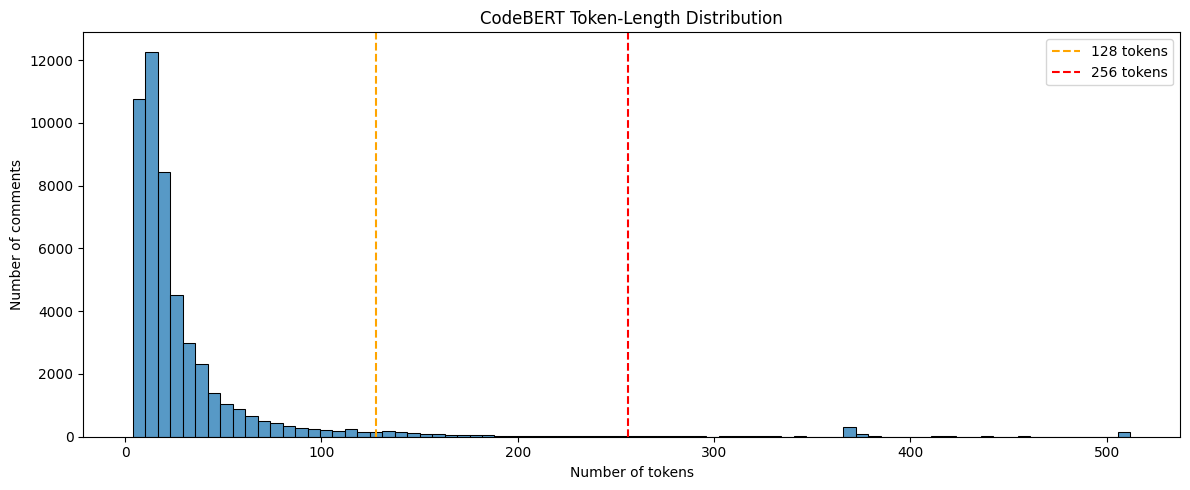

In [33]:
plt.figure(figsize=(12, 5))

sns.histplot(
    np.clip(token_lengths, 0, 512),
    bins=80,
)

plt.axvline(
    128,
    color="orange",
    linestyle="--",
    label="128 tokens",
)

plt.axvline(
    256,
    color="red",
    linestyle="--",
    label="256 tokens",
)

plt.title("CodeBERT Token-Length Distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Number of comments")
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
def to_huggingface_dataset(dataframe):
    selected_dataframe = dataframe[
        [
            TEXT_COLUMN,
            "label_id",
        ]
    ].rename(
        columns={
            "label_id": "labels",
        }
    )

    return Dataset.from_pandas(
        selected_dataframe,
        preserve_index=False,
    )


raw_datasets = DatasetDict({
    "train": to_huggingface_dataset(train_df),
    "validation": to_huggingface_dataset(validation_df),
    "test": to_huggingface_dataset(test_df),
})

print(raw_datasets)

DatasetDict({
    train: Dataset({
        features: ['commenttext', 'labels'],
        num_rows: 244295
    })
    validation: Dataset({
        features: ['commenttext', 'labels'],
        num_rows: 52349
    })
    test: Dataset({
        features: ['commenttext', 'labels'],
        num_rows: 52350
    })
})


In [35]:
def tokenize_batch(batch):
    return tokenizer(
        batch[TEXT_COLUMN],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )


tokenized_datasets = raw_datasets.map(
    tokenize_batch,
    batched=True,
    remove_columns=[TEXT_COLUMN],
    desc="Tokenizing comments",
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
)

print(tokenized_datasets)

Tokenizing comments:   0%|          | 0/244295 [00:00<?, ? examples/s]

Tokenizing comments:   0%|          | 0/52349 [00:00<?, ? examples/s]

Tokenizing comments:   0%|          | 0/52350 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 244295
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 52349
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 52350
    })
})


In [36]:
model_config = AutoConfig.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    label2id=label2id,
    id2label=id2label,
    problem_type="single_label_classification",
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    config=model_config,
)

if USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()

    # Disable caching because it conflicts with checkpointing.
    model.config.use_cache = False

print("Model:", MODEL_NAME)
print("Number of output classes:", model.config.num_labels)
print("Gradient checkpointing:", USE_GRADIENT_CHECKPOINTING)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] RobertaForSequenceClassification LOAD REPORT from: microsoft/codebert-base
Key                        | Status     | 
---------------------------+------------+-
pooler.dense.weight        | UNEXPECTED | 
pooler.dense.bias          | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: microsoft/codebert-base
Number of output classes: 6
Gradient checkpointing: False


In [37]:
def safe_metric_name(label):
    return (
        label
        .lower()
        .replace("/", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )


def compute_metrics(evaluation_prediction):
    logits, true_labels = evaluation_prediction

    predicted_labels = np.argmax(
        logits,
        axis=-1,
    )

    accuracy = accuracy_score(
        true_labels,
        predicted_labels,
    )

    balanced_accuracy = balanced_accuracy_score(
        true_labels,
        predicted_labels,
    )

    (
        macro_precision,
        macro_recall,
        macro_f1,
        _,
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0,
    )

    (
        weighted_precision,
        weighted_recall,
        weighted_f1,
        _,
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0,
    )

    (
        class_precision,
        class_recall,
        class_f1,
        _,
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=list(range(NUM_LABELS)),
        average=None,
        zero_division=0,
    )

    metrics = {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1,
    }

    for class_id in range(NUM_LABELS):
        metric_label = safe_metric_name(
            id2label[class_id]
        )

        metrics[
            f"{metric_label}_precision"
        ] = class_precision[class_id]

        metrics[
            f"{metric_label}_recall"
        ] = class_recall[class_id]

        metrics[
            f"{metric_label}_f1"
        ] = class_f1[class_id]

    return metrics

In [38]:
class ImbalanceAwareTrainer(Trainer):
    def __init__(
        self,
        *args,
        class_weights=None,
        loss_type="weighted_ce",
        focal_gamma=2.0,
        **kwargs,
    ):
        super().__init__(*args, **kwargs)

        self.class_weights = class_weights
        self.loss_type = loss_type
        self.focal_gamma = focal_gamma

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):
        labels = inputs.pop("labels")

        outputs = model(**inputs)
        logits = outputs.logits

        weights = None

        if self.class_weights is not None:
            weights = self.class_weights.to(
                device=logits.device,
                dtype=logits.dtype,
            )

        if self.loss_type == "weighted_ce":
            loss = F.cross_entropy(
                logits,
                labels,
                weight=weights,
            )

        elif self.loss_type == "weighted_focal":
            per_example_cross_entropy = F.cross_entropy(
                logits,
                labels,
                weight=weights,
                reduction="none",
            )

            probabilities = torch.softmax(
                logits,
                dim=-1,
            )

            true_class_probabilities = probabilities.gather(
                dim=1,
                index=labels.unsqueeze(1),
            ).squeeze(1)

            focal_multiplier = (
                1.0 - true_class_probabilities
            ).pow(self.focal_gamma)

            loss = (
                focal_multiplier
                * per_example_cross_entropy
            ).mean()

        else:
            raise ValueError(
                "LOSS_TYPE must be 'weighted_ce' "
                "or 'weighted_focal'."
            )

        if return_outputs:
            return loss, outputs

        return loss

In [39]:
# Cell 27: Version-compatible Kaggle TrainingArguments

import math
import inspect
import torch
import transformers

from transformers import TrainingArguments


# ================================================================
# Mixed precision
# ================================================================

# T4 and P100 should normally use FP16.
# BF16 is appropriate only when the GPU explicitly supports it.

use_bf16 = (
    torch.cuda.is_available()
    and hasattr(torch.cuda, "is_bf16_supported")
    and torch.cuda.is_bf16_supported()
)

use_fp16 = (
    torch.cuda.is_available()
    and not use_bf16
)


# ================================================================
# Calculate warmup steps manually
# ================================================================
# The installed Transformers version does not support warmup_ratio,
# so convert WARMUP_RATIO into an equivalent number of steps.

number_of_training_examples = len(
    tokenized_datasets["train"]
)

batches_per_epoch = math.ceil(
    number_of_training_examples
    / TRAIN_BATCH_SIZE
)

optimizer_steps_per_epoch = math.ceil(
    batches_per_epoch
    / GRADIENT_ACCUMULATION_STEPS
)

total_training_steps = math.ceil(
    optimizer_steps_per_epoch
    * NUM_EPOCHS
)

calculated_warmup_steps = int(
    total_training_steps
    * WARMUP_RATIO
)

# Use at least one warmup step.
calculated_warmup_steps = max(
    1,
    calculated_warmup_steps,
)


# ================================================================
# Training arguments
# ================================================================

training_parameters = {
    "output_dir": OUTPUT_DIR,

    # Optimization
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "num_train_epochs": NUM_EPOCHS,

    # Use warmup_steps instead of warmup_ratio.
    "warmup_steps": calculated_warmup_steps,

    # Batch sizes
    "per_device_train_batch_size": TRAIN_BATCH_SIZE,
    "per_device_eval_batch_size": EVAL_BATCH_SIZE,

    "gradient_accumulation_steps": (
        GRADIENT_ACCUMULATION_STEPS
    ),

    # Logging
    "logging_steps": LOGGING_STEPS,

    # Save checkpoints
    "save_steps": max(
        1,
        optimizer_steps_per_epoch,
    ),

    "save_total_limit": 2,

    # Mixed precision
    "fp16": use_fp16,
    "bf16": use_bf16,

    # Disable external experiment trackers.
    "report_to": "none",

    # Reproducibility
    "seed": SEED,

    # Data loading
    "dataloader_num_workers": 2,

    # Keep all incomplete batches.
    "dataloader_drop_last": False,

    # Compatible optimizer
    "optim": "adamw_torch",
}


# ================================================================
# Add only arguments supported by the installed version
# ================================================================

supported_parameters = inspect.signature(
    TrainingArguments.__init__
).parameters


def add_if_supported(parameter_name, value):
    if parameter_name in supported_parameters:
        training_parameters[parameter_name] = value

    else:
        print(
            f"Skipping unsupported TrainingArguments parameter: "
            f"{parameter_name}"
        )


# Evaluation strategy name differs between Transformers versions.
if "eval_strategy" in supported_parameters:
    training_parameters["eval_strategy"] = "steps"

elif "evaluation_strategy" in supported_parameters:
    training_parameters[
        "evaluation_strategy"
    ] = "steps"

else:
    print(
        "Warning: this Transformers version does not expose an "
        "evaluation-strategy parameter."
    )


# Evaluate approximately once per epoch.
add_if_supported(
    "eval_steps",
    max(1, optimizer_steps_per_epoch),
)

add_if_supported(
    "logging_strategy",
    "steps",
)

add_if_supported(
    "save_strategy",
    "steps",
)

add_if_supported(
    "load_best_model_at_end",
    True,
)

add_if_supported(
    "metric_for_best_model",
    "macro_f1",
)

add_if_supported(
    "greater_is_better",
    True,
)

add_if_supported(
    "data_seed",
    SEED,
)

add_if_supported(
    "dataloader_pin_memory",
    torch.cuda.is_available(),
)

add_if_supported(
    "remove_unused_columns",
    True,
)

add_if_supported(
    "group_by_length",
    True,
)


# ================================================================
# Final safety filter
# ================================================================
# Remove any parameter that the active Transformers version does not
# recognize. This prevents another unexpected-keyword error.

training_parameters = {
    key: value
    for key, value in training_parameters.items()
    if key in supported_parameters
}


# ================================================================
# Create TrainingArguments
# ================================================================

training_args = TrainingArguments(
    **training_parameters
)


# ================================================================
# Display configuration
# ================================================================

effective_batch_size = (
    TRAIN_BATCH_SIZE
    * GRADIENT_ACCUMULATION_STEPS
)

print("\nTrainingArguments created successfully.")
print("Transformers version:", transformers.__version__)
print("Device:", training_args.device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("FP16 enabled:", use_fp16)
print("BF16 enabled:", use_bf16)

print(
    "Number of training examples:",
    number_of_training_examples,
)

print(
    "Optimizer steps per epoch:",
    optimizer_steps_per_epoch,
)

print(
    "Estimated total training steps:",
    total_training_steps,
)

print(
    "Calculated warmup steps:",
    calculated_warmup_steps,
)

print(
    "Effective training batch size:",
    effective_batch_size,
)

print("\nParameters sent to TrainingArguments:")

for key, value in training_parameters.items():
    print(f"{key}: {value}")

Skipping unsupported TrainingArguments parameter: group_by_length

TrainingArguments created successfully.
Transformers version: 5.20.2
Device: cuda:0
GPU: Tesla T4
FP16 enabled: False
BF16 enabled: True
Number of training examples: 244295
Optimizer steps per epoch: 15269
Estimated total training steps: 76345
Calculated warmup steps: 7634
Effective training batch size: 16

Parameters sent to TrainingArguments:
output_dir: /kaggle/working/codebert_cppsatd_multiclass
learning_rate: 2e-05
weight_decay: 0.01
num_train_epochs: 5
warmup_steps: 7634
per_device_train_batch_size: 8
per_device_eval_batch_size: 16
gradient_accumulation_steps: 2
logging_steps: 200
save_steps: 15269
save_total_limit: 2
fp16: False
bf16: True
report_to: none
seed: 42
dataloader_num_workers: 2
dataloader_drop_last: False
optim: adamw_torch
eval_strategy: steps
eval_steps: 15269
logging_strategy: steps
save_strategy: steps
load_best_model_at_end: True
metric_for_best_model: macro_f1
greater_is_better: True
data_seed: 

In [40]:
trainer_parameters = {
    "model": model,
    "args": training_args,

    "train_dataset": tokenized_datasets["train"],
    "eval_dataset": tokenized_datasets["validation"],

    "data_collator": data_collator,
    "compute_metrics": compute_metrics,

    "class_weights": class_weights,
    "loss_type": LOSS_TYPE,
    "focal_gamma": FOCAL_GAMMA,

    "callbacks": [
        EarlyStoppingCallback(
            early_stopping_patience=EARLY_STOPPING_PATIENCE
        )
    ],
}

trainer_signature = inspect.signature(
    Trainer.__init__
).parameters

if "processing_class" in trainer_signature:
    trainer_parameters["processing_class"] = tokenizer
else:
    trainer_parameters["tokenizer"] = tokenizer

trainer = ImbalanceAwareTrainer(
    **trainer_parameters
)

print("Trainer created.")
print("Weight strategy:", WEIGHT_STRATEGY)
print("Loss type:", LOSS_TYPE)

Trainer created.
Weight strategy: sqrt
Loss type: weighted_ce


In [41]:
print("Training examples:", len(train_df))
print("Validation examples:", len(validation_df))
print("Maximum sequence length:", MAX_LENGTH)
print("Epochs:", NUM_EPOCHS)

train_result = trainer.train()

print("Training completed.")

Training examples: 244295
Validation examples: 52349
Maximum sequence length: 256
Epochs: 5


Step,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Non Satd Precision,Non Satd Recall,Non Satd F1,Design Code Debt Precision,Design Code Debt Recall,Design Code Debt F1,Requirement Precision,Requirement Recall,Requirement F1,Defect Precision,Defect Recall,Defect F1,Test Precision,Test Recall,Test F1,Documentation Precision,Documentation Recall,Documentation F1
15269,0.133257,0.055613,0.993085,0.654483,0.832457,0.654483,0.691631,0.992794,0.993085,0.992830,0.997813,0.999526,0.998669,0.858834,0.870729,0.864741,0.848780,0.700201,0.767365,0.577778,0.464286,0.514851,0.711538,0.725490,0.718447,1.000000,0.166667,0.285714
30538,0.049468,0.070223,0.993142,0.725468,0.773198,0.725468,0.745853,0.993002,0.993142,0.993047,0.998205,0.998973,0.998589,0.873346,0.853186,0.863148,0.783730,0.794769,0.789211,0.717949,0.500000,0.589474,0.765957,0.705882,0.734694,0.500000,0.500000,0.500000
38175,0.022979,0.079838,0.993448,0.697017,0.751616,0.697017,0.721301,0.993247,0.993448,0.993329,0.998304,0.999191,0.998747,0.874302,0.867036,0.870654,0.804167,0.776660,0.790174,0.682927,0.500000,0.577320,0.750000,0.705882,0.727273,0.400000,0.333333,0.363636


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed.


In [42]:
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

trainer.save_metrics(
    "train",
    train_result.metrics,
)

trainer.save_state()

print("Model saved to:", OUTPUT_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /kaggle/working/codebert_cppsatd_multiclass


In [43]:
validation_metrics = trainer.evaluate(
    eval_dataset=tokenized_datasets["validation"],
    metric_key_prefix="validation",
)

print("Validation metrics:\n")

for metric_name, metric_value in sorted(
    validation_metrics.items()
):
    if isinstance(metric_value, float):
        print(
            f"{metric_name}: "
            f"{metric_value:.6f}"
        )
    else:
        print(
            f"{metric_name}: "
            f"{metric_value}"
        )


trainer.save_metrics(
    "validation",
    validation_metrics,
)

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Step,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Non Satd Precision,Non Satd Recall,Non Satd F1,Design Code Debt Precision,Design Code Debt Recall,Design Code Debt F1,Requirement Precision,Requirement Recall,Requirement F1,Defect Precision,Defect Recall,Defect F1,Test Precision,Test Recall,Test F1,Documentation Precision,Documentation Recall,Documentation F1
0.022979,0.070223,38175,0.993142,0.725468,0.773198,0.725468,0.745853,0.993002,0.993142,0.993047,0.998205,0.998973,0.998589,0.873346,0.853186,0.863148,0.783730,0.794769,0.789211,0.717949,0.500000,0.589474,0.765957,0.705882,0.734694,0.500000,0.500000,0.500000


Validation metrics:

validation_accuracy: 0.993142
validation_balanced_accuracy: 0.725468
validation_defect_f1: 0.589474
validation_defect_precision: 0.717949
validation_defect_recall: 0.500000
validation_design_code_debt_f1: 0.863148
validation_design_code_debt_precision: 0.873346
validation_design_code_debt_recall: 0.853186
validation_documentation_f1: 0.500000
validation_documentation_precision: 0.500000
validation_documentation_recall: 0.500000
validation_loss: 0.070223
validation_macro_f1: 0.745853
validation_macro_precision: 0.773198
validation_macro_recall: 0.725468
validation_non_satd_f1: 0.998589
validation_non_satd_precision: 0.998205
validation_non_satd_recall: 0.998973
validation_requirement_f1: 0.789211
validation_requirement_precision: 0.783730
validation_requirement_recall: 0.794769
validation_test_f1: 0.734694
validation_test_precision: 0.765957
validation_test_recall: 0.705882
validation_weighted_f1: 0.993047
validation_weighted_precision: 0.993002
validation_weighted_

In [44]:
test_output = trainer.predict(
    tokenized_datasets["test"],
    metric_key_prefix="test",
)

test_logits = test_output.predictions
test_labels = test_output.label_ids

test_predictions = np.argmax(
    test_logits,
    axis=-1,
)


print("Test metrics:\n")

for metric_name, metric_value in sorted(
    test_output.metrics.items()
):
    if isinstance(metric_value, float):
        print(
            f"{metric_name}: "
            f"{metric_value:.6f}"
        )
    else:
        print(
            f"{metric_name}: "
            f"{metric_value}"
        )


trainer.save_metrics(
    "test",
    test_output.metrics,
)

Test metrics:

test_accuracy: 0.992837
test_balanced_accuracy: 0.716931
test_defect_f1: 0.576577
test_defect_precision: 0.581818
test_defect_recall: 0.571429
test_design_code_debt_f1: 0.849533
test_design_code_debt_precision: 0.859168
test_design_code_debt_recall: 0.840111
test_documentation_f1: 0.400000
test_documentation_precision: 0.500000
test_documentation_recall: 0.333333
test_f1: 0.804124
test_loss: 0.065591
test_macro_f1: 0.737382
test_macro_precision: 0.764156
test_macro_recall: 0.716931
test_non_satd_f1: 0.998490
test_non_satd_precision: 0.998146
test_non_satd_recall: 0.998835
test_precision: 0.847826
test_recall: 0.764706
test_requirement_f1: 0.795569
test_requirement_precision: 0.797980
test_requirement_recall: 0.793173
test_runtime: 320.189500
test_samples_per_second: 163.497000
test_steps_per_second: 5.109000
test_weighted_f1: 0.992772
test_weighted_precision: 0.992720
test_weighted_recall: 0.992837


In [45]:
# Multiclass classification report

# Safety checks
required_variables = [
    "test_labels",
    "test_predictions",
    "NUM_LABELS",
    "LABEL_ORDER",
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the test-evaluation cells first. "
        f"Missing variables: {missing_variables}"
    )

if len(LABEL_ORDER) != NUM_LABELS:
    raise ValueError(
        f"LABEL_ORDER has {len(LABEL_ORDER)} classes, "
        f"but NUM_LABELS is {NUM_LABELS}."
    )

test_classification_report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(NUM_LABELS)),
    target_names=LABEL_ORDER,
    digits=4,
    zero_division=0,
)

print(test_classification_report)

                  precision    recall  f1-score   support

        NON-SATD     0.9981    0.9988    0.9985     50657
DESIGN/CODE DEBT     0.8592    0.8401    0.8495      1082
     REQUIREMENT     0.7980    0.7932    0.7956       498
          DEFECT     0.5818    0.5714    0.5766        56
            TEST     0.8478    0.7647    0.8041        51
   DOCUMENTATION     0.5000    0.3333    0.4000         6

        accuracy                         0.9928     52350
       macro avg     0.7642    0.7169    0.7374     52350
    weighted avg     0.9927    0.9928    0.9928     52350



In [46]:
# Save the multiclass classification report as TXT and CSV

import os
import pandas as pd

# Use the model's ID-to-label mapping to guarantee the correct order.
report_label_ids = list(range(NUM_LABELS))

report_label_names = [
    trainer.model.config.id2label[class_id]
    for class_id in report_label_ids
]

# Create the text report.
test_classification_report = classification_report(
    test_labels,
    test_predictions,
    labels=report_label_ids,
    target_names=report_label_names,
    digits=4,
    zero_division=0,
)

# Create the dictionary version for CSV.
report_dictionary = classification_report(
    test_labels,
    test_predictions,
    labels=report_label_ids,
    target_names=report_label_names,
    output_dict=True,
    zero_division=0,
)

report_dataframe = (
    pd.DataFrame(report_dictionary)
    .transpose()
)

# Create the output directory if needed.
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True,
)

text_report_path = os.path.join(
    OUTPUT_DIR,
    "test_classification_report.txt",
)

csv_report_path = os.path.join(
    OUTPUT_DIR,
    "test_classification_report.csv",
)

# Save the text report.
with open(
    text_report_path,
    "w",
    encoding="utf-8",
) as file:
    file.write(test_classification_report)

# Save the table report.
report_dataframe.to_csv(
    csv_report_path,
    index=True,
)

print(test_classification_report)

print("\nSaved text report to:")
print(text_report_path)

print("\nSaved CSV report to:")
print(csv_report_path)

display(report_dataframe)

                  precision    recall  f1-score   support

        NON-SATD     0.9981    0.9988    0.9985     50657
DESIGN/CODE DEBT     0.8592    0.8401    0.8495      1082
     REQUIREMENT     0.7980    0.7932    0.7956       498
          DEFECT     0.5818    0.5714    0.5766        56
            TEST     0.8478    0.7647    0.8041        51
   DOCUMENTATION     0.5000    0.3333    0.4000         6

        accuracy                         0.9928     52350
       macro avg     0.7642    0.7169    0.7374     52350
    weighted avg     0.9927    0.9928    0.9928     52350


Saved text report to:
/kaggle/working/codebert_cppsatd_multiclass/test_classification_report.txt

Saved CSV report to:
/kaggle/working/codebert_cppsatd_multiclass/test_classification_report.csv


,precision,recall,f1-score,support
NON-SATD,0.998146,0.998835,0.998490,50657.000000
DESIGN/CODE DEBT,0.859168,0.840111,0.849533,1082.000000
REQUIREMENT,0.797980,0.793173,0.795569,498.000000
DEFECT,0.581818,0.571429,0.576577,56.000000
TEST,0.847826,0.764706,0.804124,51.000000
DOCUMENTATION,0.500000,0.333333,0.400000,6.000000
accuracy,0.992837,0.992837,0.992837,0.992837
macro avg,0.764156,0.716931,0.737382,52350.000000
weighted avg,0.992720,0.992837,0.992772,52350.000000


In [47]:
# Create and display the multiclass confusion matrix

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix


# Use the model's actual label mapping in ID order.
report_label_ids = list(range(NUM_LABELS))

report_label_names = [
    trainer.model.config.id2label[class_id]
    for class_id in report_label_ids
]


# Validate the label configuration.
if len(report_label_names) != NUM_LABELS:
    raise ValueError(
        f"Found {len(report_label_names)} label names, "
        f"but NUM_LABELS is {NUM_LABELS}."
    )


# Calculate the confusion matrix.
confusion_matrix_values = confusion_matrix(
    test_labels,
    test_predictions,
    labels=report_label_ids,
)


# Convert it to a readable DataFrame.
confusion_matrix_dataframe = pd.DataFrame(
    confusion_matrix_values,

    index=[
        f"Actual: {label}"
        for label in report_label_names
    ],

    columns=[
        f"Predicted: {label}"
        for label in report_label_names
    ],
)


display(confusion_matrix_dataframe)

,Predicted: NON-SATD,Predicted: DESIGN/CODE DEBT,Predicted: REQUIREMENT,Predicted: DEFECT,Predicted: TEST,Predicted: DOCUMENTATION
Actual: NON-SATD,50598,50,6,3,0,0
Actual: DESIGN/CODE DEBT,71,909,84,14,4,0
Actual: REQUIREMENT,12,84,395,4,1,2
Actual: DEFECT,9,10,3,32,2,0
Actual: TEST,1,4,5,2,39,0
Actual: DOCUMENTATION,1,1,2,0,0,2


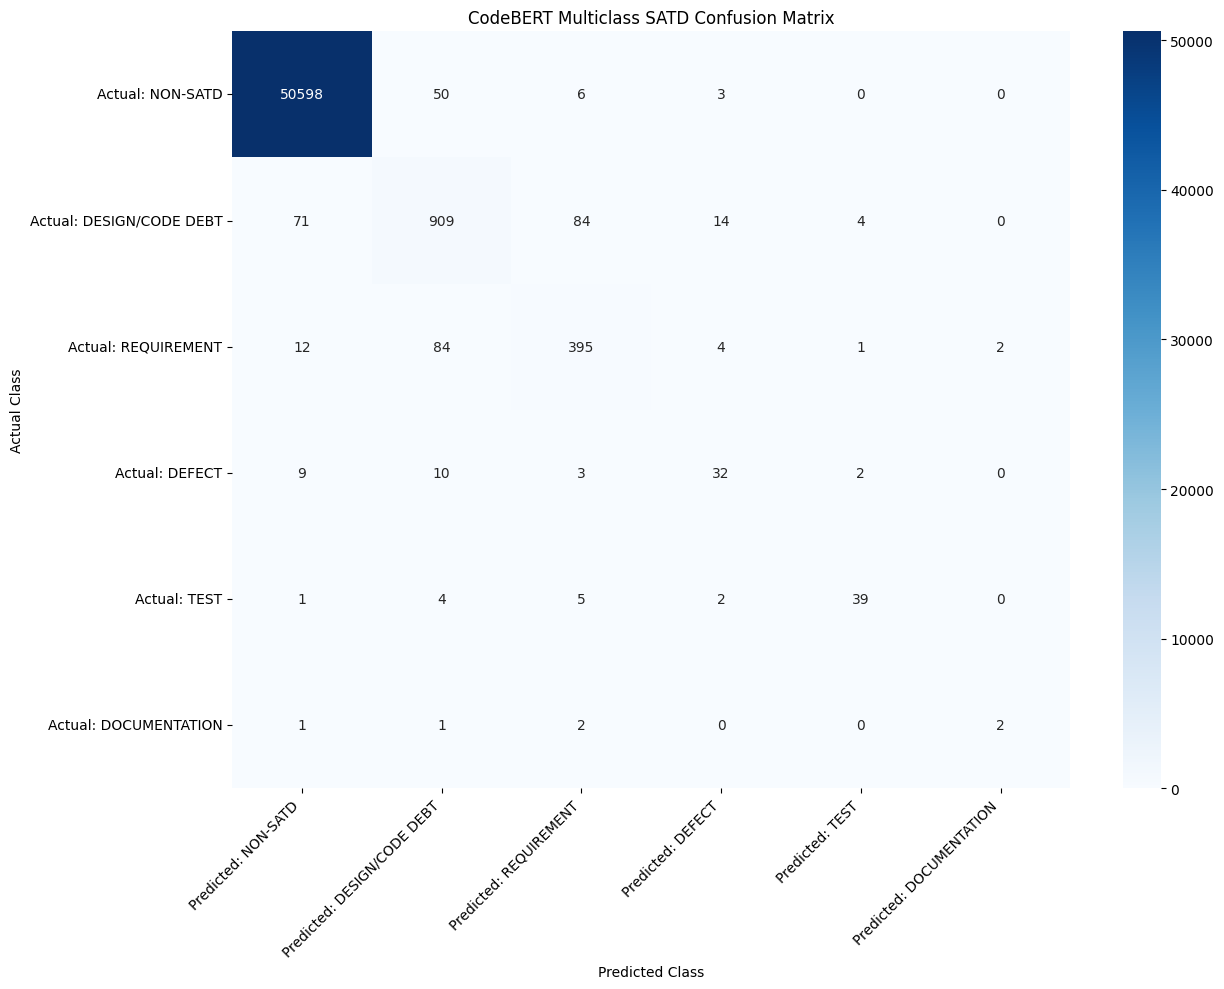

In [48]:
plt.figure(figsize=(13, 10))

sns.heatmap(
    confusion_matrix_dataframe,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("CodeBERT Multiclass SATD Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

,Predicted: NON-SATD,Predicted: DESIGN/CODE DEBT,Predicted: REQUIREMENT,Predicted: DEFECT,Predicted: TEST,Predicted: DOCUMENTATION
Actual: NON-SATD,0.998835,0.000987,0.000118,0.000059,0.000000,0.000000
Actual: DESIGN/CODE DEBT,0.065619,0.840111,0.077634,0.012939,0.003697,0.000000
Actual: REQUIREMENT,0.024096,0.168675,0.793173,0.008032,0.002008,0.004016
Actual: DEFECT,0.160714,0.178571,0.053571,0.571429,0.035714,0.000000
Actual: TEST,0.019608,0.078431,0.098039,0.039216,0.764706,0.000000
Actual: DOCUMENTATION,0.166667,0.166667,0.333333,0.000000,0.000000,0.333333


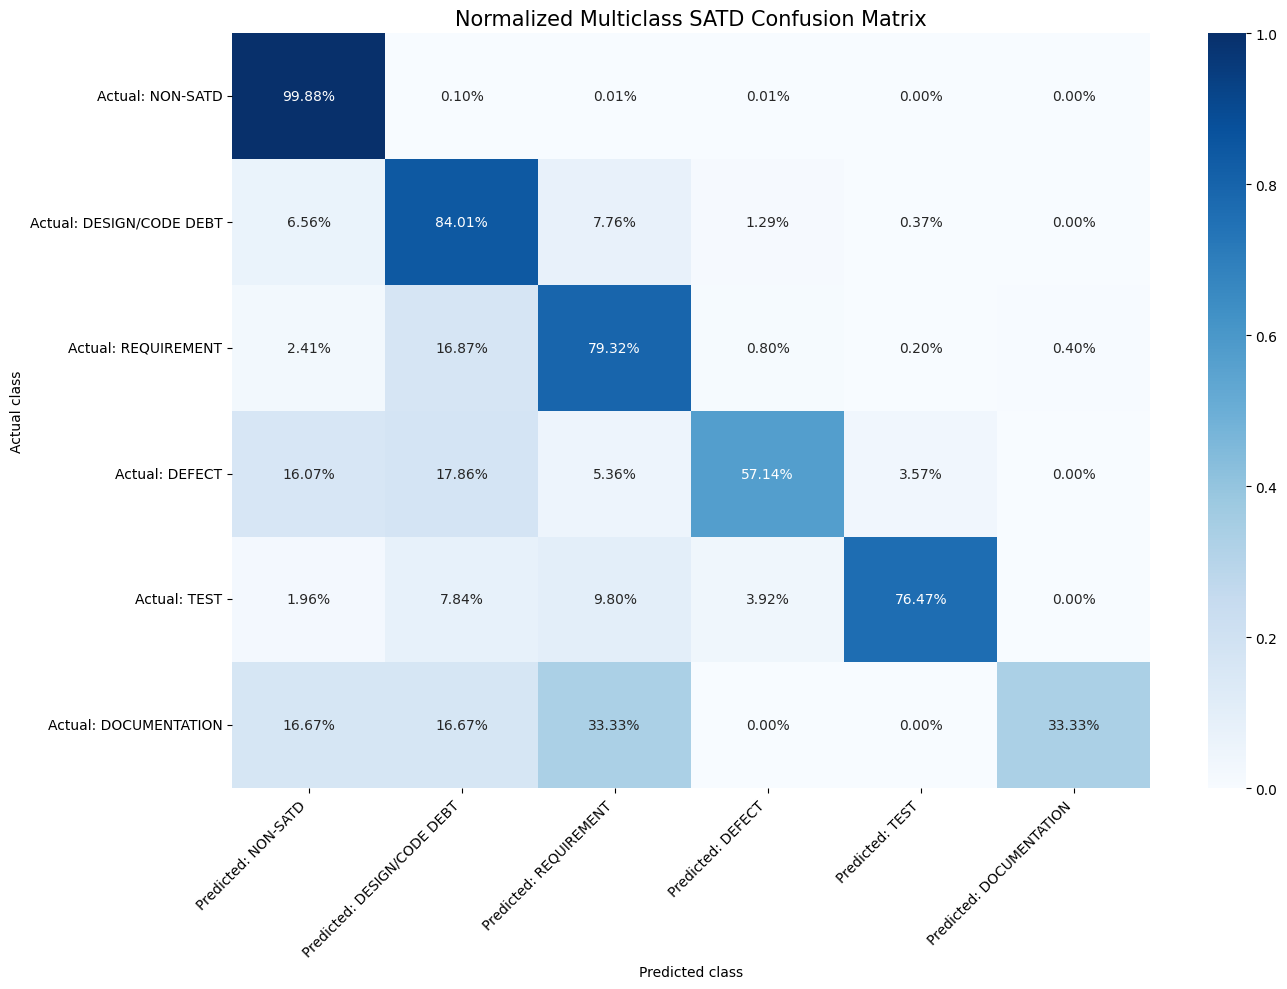

In [49]:
# Create and plot the normalized multiclass confusion matrix

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Always derive names from the trained model in class-ID order.
report_label_ids = list(range(NUM_LABELS))

report_label_names = [
    trainer.model.config.id2label[class_id]
    for class_id in report_label_ids
]


# Recreate the raw confusion matrix if it is not already available.
confusion_matrix_values = confusion_matrix(
    test_labels,
    test_predictions,
    labels=report_label_ids,
)


# Normalize each row.
# Every row represents one actual class, so these percentages show
# how examples of that class were distributed across predictions.
row_totals = confusion_matrix_values.sum(
    axis=1,
    keepdims=True,
)

normalized_confusion_matrix = np.divide(
    confusion_matrix_values,
    row_totals,

    out=np.zeros_like(
        confusion_matrix_values,
        dtype=float,
    ),

    where=row_totals != 0,
)


# Build the labeled DataFrame using report_label_names,
# not the undefined label_names variable.
normalized_confusion_dataframe = pd.DataFrame(
    normalized_confusion_matrix,

    index=[
        f"Actual: {label}"
        for label in report_label_names
    ],

    columns=[
        f"Predicted: {label}"
        for label in report_label_names
    ],
)


# Display the numerical table.
display(normalized_confusion_dataframe)


# Plot the normalized confusion matrix.
plt.figure(figsize=(14, 10))

sns.heatmap(
    normalized_confusion_dataframe,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar=True,
)

plt.title(
    "Normalized Multiclass SATD Confusion Matrix",
    fontsize=15,
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [50]:
# Save individual predictions and class probabilities

import os
import re
import numpy as np
import pandas as pd
import torch


def make_safe_column_name(class_name):
    """
    Convert a class name into a safe CSV column name.

    Example:
    DESIGN/CODE DEBT -> design_code_debt
    """

    safe_name = str(class_name).strip().lower()

    # Replace spaces, slashes, and hyphens with underscores.
    safe_name = re.sub(
        r"[\s/\-]+",
        "_",
        safe_name,
    )

    # Remove any remaining unsupported characters.
    safe_name = re.sub(
        r"[^a-z0-9_]",
        "",
        safe_name,
    )

    # Remove duplicate and surrounding underscores.
    safe_name = re.sub(
        r"_+",
        "_",
        safe_name,
    ).strip("_")

    return safe_name


# Recreate probabilities if they are not currently in memory.
if "test_probabilities" not in globals():
    test_probabilities = torch.softmax(
        torch.tensor(test_logits),
        dim=-1,
    ).cpu().numpy()


# Validate that rows align.
if len(test_df) != len(test_labels):
    raise ValueError(
        f"test_df contains {len(test_df)} rows, but "
        f"test_labels contains {len(test_labels)} rows."
    )

if len(test_labels) != len(test_predictions):
    raise ValueError(
        f"test_labels contains {len(test_labels)} values, but "
        f"test_predictions contains "
        f"{len(test_predictions)} values."
    )

if test_probabilities.shape != (
    len(test_labels),
    NUM_LABELS,
):
    raise ValueError(
        "Unexpected probability-array shape.\n"
        f"Expected: {(len(test_labels), NUM_LABELS)}\n"
        f"Actual: {test_probabilities.shape}"
    )


# Copy the original test records.
prediction_df = test_df.copy().reset_index(
    drop=True
)


# Add readable true and predicted labels.
prediction_df["true_label"] = [
    trainer.model.config.id2label[int(class_id)]
    for class_id in test_labels
]

prediction_df["predicted_label"] = [
    trainer.model.config.id2label[int(class_id)]
    for class_id in test_predictions
]


# Add prediction confidence and correctness.
prediction_df["prediction_confidence"] = (
    test_probabilities.max(axis=1)
)

prediction_df["is_correct"] = (
    prediction_df["true_label"]
    == prediction_df["predicted_label"]
)


# Add one probability column per class.
for class_id in range(NUM_LABELS):
    class_name = trainer.model.config.id2label[
        class_id
    ]

    safe_class_name = make_safe_column_name(
        class_name
    )

    prediction_df[
        f"probability_{safe_class_name}"
    ] = test_probabilities[:, class_id]


# Create the output directory.
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True,
)


# Save all predictions.
predictions_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv",
)

prediction_df.to_csv(
    predictions_path,
    index=False,
)


# Save misclassified examples separately.
misclassified_df = prediction_df[
    ~prediction_df["is_correct"]
].copy()

misclassified_df = misclassified_df.sort_values(
    by="prediction_confidence",
    ascending=False,
)

misclassifications_path = os.path.join(
    OUTPUT_DIR,
    "test_misclassifications.csv",
)

misclassified_df.to_csv(
    misclassifications_path,
    index=False,
)


print("Saved all predictions to:")
print(predictions_path)

print("\nSaved misclassified predictions to:")
print(misclassifications_path)

print("\nNumber of test examples:", len(prediction_df))
print(
    "Correct predictions:",
    int(prediction_df["is_correct"].sum()),
)
print(
    "Incorrect predictions:",
    len(misclassified_df),
)

display(prediction_df.head())

Saved all predictions to:
/kaggle/working/codebert_cppsatd_multiclass/test_predictions.csv

Saved misclassified predictions to:
/kaggle/working/codebert_cppsatd_multiclass/test_misclassifications.csv

Number of test examples: 52350
Correct predictions: 51975
Incorrect predictions: 375


,commenttext,annotation,label_id,true_label,predicted_label,prediction_confidence,is_correct,probability_non_satd,probability_design_code_debt,probability_requirement,probability_defect,probability_test,probability_documentation
0,"// If this is a call, evaluate it. Calls are h...",NON-SATD,0,NON-SATD,NON-SATD,0.999990,True,0.999990,0.000004,0.000002,0.000002,4.958077e-07,5.976044e-07
1,/* [:space:] or \s */,NON-SATD,0,NON-SATD,NON-SATD,0.999991,True,0.999991,0.000003,0.000002,0.000002,3.753888e-07,5.306154e-07
2,/* stream complete */ /* Stream status */,NON-SATD,0,NON-SATD,NON-SATD,0.999993,True,0.999993,0.000002,0.000002,0.000002,3.808384e-07,5.241930e-07
3,// Don't pad the batch dimension.,NON-SATD,0,NON-SATD,NON-SATD,0.999992,True,0.999992,0.000003,0.000002,0.000002,3.687584e-07,5.298799e-07
4,// TENSORFLOW_CC_OPS_CONST_OP_H_,NON-SATD,0,NON-SATD,NON-SATD,0.999993,True,0.999993,0.000002,0.000002,0.000002,3.949037e-07,5.245246e-07


In [51]:
misclassified_df = prediction_df[
    ~prediction_df["is_correct"]
].copy()

misclassified_df = misclassified_df.sort_values(
    by="prediction_confidence",
    ascending=False,
)

misclassifications_path = os.path.join(
    OUTPUT_DIR,
    "test_misclassifications.csv",
)

misclassified_df.to_csv(
    misclassifications_path,
    index=False,
)

print("Number of test errors:", len(misclassified_df))

print("Saved misclassifications to:")
print(misclassifications_path)

display(
    misclassified_df[
        [
            TEXT_COLUMN,
            "true_label",
            "predicted_label",
            "prediction_confidence",
        ]
    ].head(20)
)

Number of test errors: 375
Saved misclassifications to:
/kaggle/working/codebert_cppsatd_multiclass/test_misclassifications.csv


,commenttext,true_label,predicted_label,prediction_confidence
35741,// This add (param0 + 0) can be simplified.,DESIGN/CODE DEBT,NON-SATD,0.999992
7263,// Require to do additional renames.,REQUIREMENT,NON-SATD,0.999992
40720,/// If this gets too expensive in terms of cop...,DESIGN/CODE DEBT,NON-SATD,0.999991
28059,// XXX wording,DESIGN/CODE DEBT,NON-SATD,0.999991
4734,"// Use OpIAdd, instead of OpBitcast to do the ...",DESIGN/CODE DEBT,NON-SATD,0.999991
12805,/*********************************************...,DESIGN/CODE DEBT,NON-SATD,0.999990
1921,// Modify the quantized fused function to do d...,DESIGN/CODE DEBT,NON-SATD,0.999990
34261,// Suggest removing `nonisolated` as it is als...,REQUIREMENT,NON-SATD,0.999989
51401,// We are required to do bounds checking.,REQUIREMENT,NON-SATD,0.999986
24473,/* Copyright 2018 The TensorFlow Authors. All ...,DESIGN/CODE DEBT,NON-SATD,0.999984


In [52]:
confusion_analysis = (
    misclassified_df
    .groupby(
        [
            "true_label",
            "predicted_label",
        ]
    )
    .size()
    .reset_index(name="error_count")
    .sort_values(
        by="error_count",
        ascending=False,
    )
)

display(confusion_analysis.head(30))

,true_label,predicted_label,error_count
6,DESIGN/CODE DEBT,REQUIREMENT,84
15,REQUIREMENT,DESIGN/CODE DEBT,84
5,DESIGN/CODE DEBT,NON-SATD,71
12,NON-SATD,DESIGN/CODE DEBT,50
4,DESIGN/CODE DEBT,DEFECT,14
17,REQUIREMENT,NON-SATD,12
0,DEFECT,DESIGN/CODE DEBT,10
1,DEFECT,NON-SATD,9
13,NON-SATD,REQUIREMENT,6
22,TEST,REQUIREMENT,5


In [53]:
non_satd_id = label2id.get("NON-SATD")

if non_satd_id is None:
    raise ValueError(
        "The label 'NON-SATD' was not found."
    )


# 0 = NON-SATD
# 1 = Any type of SATD
binary_true_labels = (
    test_labels != non_satd_id
).astype(int)

binary_predictions = (
    test_predictions != non_satd_id
).astype(int)


binary_report = classification_report(
    binary_true_labels,
    binary_predictions,

    labels=[0, 1],
    target_names=[
        "NON-SATD",
        "SATD",
    ],

    digits=4,
    zero_division=0,
)

print(binary_report)

              precision    recall  f1-score   support

    NON-SATD     0.9981    0.9988    0.9985     50657
        SATD     0.9644    0.9445    0.9543      1693

    accuracy                         0.9971     52350
   macro avg     0.9813    0.9717    0.9764     52350
weighted avg     0.9971    0.9971    0.9971     52350



In [54]:
binary_report_path = os.path.join(
    OUTPUT_DIR,
    "binary_satd_classification_report.txt",
)

with open(
    binary_report_path,
    "w",
    encoding="utf-8",
) as file:
    file.write(binary_report)

print("Saved binary report to:")
print(binary_report_path)

Saved binary report to:
/kaggle/working/codebert_cppsatd_multiclass/binary_satd_classification_report.txt


In [55]:
INFERENCE_MODEL_PATH = OUTPUT_DIR

inference_device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

inference_tokenizer = AutoTokenizer.from_pretrained(
    INFERENCE_MODEL_PATH
)

inference_model = (
    AutoModelForSequenceClassification
    .from_pretrained(INFERENCE_MODEL_PATH)
    .to(inference_device)
)

inference_model.eval()

print("Inference device:", inference_device)
print("Inference model loaded successfully.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Inference device: cuda
Inference model loaded successfully.


In [56]:
import torch


def predict_satd_type(comment):
    """Predict the SATD category of one source-code comment."""

    comment = str(comment).strip()

    if not comment:
        raise ValueError("The comment cannot be empty.")

    # Tokenize the comment.
    encoded_comment = inference_tokenizer(
        comment,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding=True,
    )

    # Move every tensor to the model's device.
    encoded_comment = {
        key: value.to(inference_device)
        for key, value in encoded_comment.items()
    }

    # Perform inference.
    inference_model.eval()

    with torch.no_grad():
        outputs = inference_model(**encoded_comment)
        logits = outputs.logits

        probabilities = torch.softmax(
            logits,
            dim=-1,
        )[0]

    # Highest-probability class.
    predicted_id = int(
        torch.argmax(probabilities).item()
    )

    predicted_label = (
        inference_model.config.id2label.get(
            predicted_id,
            str(predicted_id),
        )
    )

    # Probability for every class.
    all_probabilities = {
        inference_model.config.id2label.get(
            class_id,
            str(class_id),
        ): float(probability.item())
        for class_id, probability
        in enumerate(probabilities)
    }

    all_probabilities = dict(
        sorted(
            all_probabilities.items(),
            key=lambda item: item[1],
            reverse=True,
        )
    )

    # Combined probability of all SATD classes.
    non_satd_probability = float(
        all_probabilities.get(
            "NON-SATD",
            0.0,
        )
    )

    satd_probability = (
        1.0 - non_satd_probability
    )

    # This return statement must remain inside the function.
    return {
        "predicted_id": predicted_id,
        "predicted_label": predicted_label,
        "confidence": float(
            probabilities[predicted_id].item()
        ),
        "satd_probability": float(
            satd_probability
        ),
        "all_probabilities": (
            all_probabilities
        ),
    }


print("Prediction function replaced successfully.")

Prediction function replaced successfully.


In [57]:
example_comment = """
TODO: This workaround should be removed when the parser
supports nested template arguments correctly.
"""

prediction_result = predict_satd_type(
    example_comment
)

print(
    json.dumps(
        prediction_result,
        indent=2,
        ensure_ascii=False,
    )
)

{
  "predicted_id": 1,
  "predicted_label": "DESIGN/CODE DEBT",
  "confidence": 0.9987066984176636,
  "satd_probability": 0.9998297102283686,
  "all_probabilities": {
    "DESIGN/CODE DEBT": 0.9987066984176636,
    "TEST": 0.0004979908117093146,
    "REQUIREMENT": 0.00046760900295339525,
    "NON-SATD": 0.00017028977163136005,
    "DEFECT": 9.707798017188907e-05,
    "DOCUMENTATION": 6.034237230778672e-05
  }
}


In [58]:
example_comments = [
    "TODO: Refactor this method because it is too complex.",

    "FIXME: This produces an incorrect result when the input is empty.",

    "TODO: Add tests for the timeout condition.",

    "This function returns the current configuration value.",

    "TODO: Document the expected behavior of this class.",

    "FIXME: Implement support for compressed files.",
]


batch_results = []

for comment in example_comments:
    result = predict_satd_type(comment)

    batch_results.append({
        "comment": comment,
        "predicted_label": result["predicted_label"],
        "confidence": result["confidence"],
    })


batch_prediction_df = pd.DataFrame(
    batch_results
)

display(batch_prediction_df)

,comment,predicted_label,confidence
0,TODO: Refactor this method because it is too c...,DESIGN/CODE DEBT,0.998113
1,FIXME: This produces an incorrect result when ...,DEFECT,0.996187
2,TODO: Add tests for the timeout condition.,TEST,0.999275
3,This function returns the current configuratio...,NON-SATD,0.999993
4,TODO: Document the expected behavior of this c...,DOCUMENTATION,0.998709
5,FIXME: Implement support for compressed files.,REQUIREMENT,0.999061


In [59]:
import shutil

archive_path = shutil.make_archive(
    base_name="/kaggle/working/codebert_cppsatd_multiclass",
    format="zip",
    root_dir=OUTPUT_DIR,
)

print("Created model archive:")
print(archive_path)

Created model archive:
/kaggle/working/codebert_cppsatd_multiclass.zip


In [60]:
import os
import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    average_precision_score,
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
)

# Change this to the actual Kaggle path.
DATA_PATH = "/kaggle/input/datasets/ahmedamir7/comment-satd/comment.csv"

# Path containing your saved trained CodeBERT model.
MODEL_PATH = "/kaggle/working/codebert_cppsatd_multiclass"

TEXT_COLUMN = "comment"
GROUND_TRUTH_COLUMN = "satd"

MAX_LENGTH = 256
INFERENCE_BATCH_SIZE = 32

PREDICTION_OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "satd_binary_predictions.csv",
)

ERROR_OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "satd_binary_errors.csv",
)

print("Configuration loaded.")

Configuration loaded.


In [61]:
file_extension = Path(DATA_PATH).suffix.lower()

if file_extension == ".csv":
    inference_df = pd.read_csv(
        DATA_PATH,
        low_memory=False,
    )

elif file_extension in [".xlsx", ".xls"]:
    inference_df = pd.read_excel(
        DATA_PATH,
    )

else:
    raise ValueError(
        f"Unsupported file type: {file_extension}. "
        "Use CSV, XLSX, or XLS."
    )

print("Dataset shape:", inference_df.shape)

print("\nColumns:")
print(inference_df.columns.tolist())

display(inference_df.head())


Dataset shape: (50000, 10)

Columns:
['id', 'repository', 'comment', 'hash', 'satd', 'type', 'code_before', 'code_after', 'code_method', 'url']


,id,repository,comment,hash,satd,type,code_before,code_after,code_method,url
0,7,3,/**\n * This method asserts that the weapon ob...,837aadfa208f05c9171aa53e9156ee12cb77dc98,no,NaN,* Testing {@link ElfBlacksmith} to produce a ...,"private void verifyWeapon(Weapon weapon, Wea...",NaN,https://github.com/iluwatar/java-design-patter...
1,47,3,/**\n * Verify if the fatigue level is set pro...,281b86cb749852a937303fcc83758b2c2eed35c3,no,NaN,Action action = new Action(model);\n assert...,@Test\nvoid testSetFatigue() {\n final var mo...,NaN,https://github.com/iluwatar/java-design-patter...
2,83,3,/**\n * Sets up.\n */,673522a0b7d794bc41e62cc6aa5749e7c4aaec97,no,NaN,import static org.mockito.Mockito.*;\n\n/**\n ...,@BeforeEach\nvoid setUp() {\n paymentService ...,NaN,https://github.com/iluwatar/java-design-patter...
3,108,3,/**\n * tests {@link CustomerResource}.\n */,8708eba66eb1f38b96e19ac3a011fd0ba1c8f6b0,no,NaN,*/\npackage com.iluwatar.datatransfer.custome...,class CustomerResourceTest {\n\n @Test\n voi...,NaN,https://github.com/iluwatar/java-design-patter...
4,138,3,/*\n * This project is licensed under the MIT ...,38867c431007f0067e25f2dbb91e05d8fda960c8,no,NaN,NaN,package com.iluwatar.execute.around;\n\nimport...,NaN,https://github.com/iluwatar/java-design-patter...


In [62]:
if TEXT_COLUMN not in inference_df.columns:
    raise ValueError(
        f"Text column '{TEXT_COLUMN}' was not found.\n"
        f"Available columns: {inference_df.columns.tolist()}"
    )

if GROUND_TRUTH_COLUMN not in inference_df.columns:
    print(
        f"Warning: '{GROUND_TRUTH_COLUMN}' was not found. "
        "Predictions can still be generated, but automatic "
        "evaluation will not be possible."
    )

print("Comment column:", TEXT_COLUMN)

if GROUND_TRUTH_COLUMN in inference_df.columns:
    print("Ground-truth column:", GROUND_TRUTH_COLUMN)

Comment column: comment
Ground-truth column: satd


In [63]:
# Preserve the complete original dataset for output and evaluation.
original_inference_df = inference_df.copy()


# Save ground-truth labels separately before removing them.
if GROUND_TRUTH_COLUMN in inference_df.columns:
    hidden_ground_truth = (
        inference_df[GROUND_TRUTH_COLUMN]
        .copy()
    )
else:
    hidden_ground_truth = None


# Columns that must never be passed to the model.
columns_hidden_from_model = [
    column
    for column in [
        "satd",
        "type",
    ]
    if column in inference_df.columns
]


# Create a safe inference DataFrame without labels.
model_input_df = inference_df.drop(
    columns=columns_hidden_from_model,
).copy()


print(
    "Columns hidden from the model:",
    columns_hidden_from_model,
)

print("\nColumns available in model_input_df:")
print(model_input_df.columns.tolist())


# Confirm that the SATD label is absent.
assert "satd" not in model_input_df.columns
assert "type" not in model_input_df.columns

print("\nThe SATD and type columns are hidden successfully.")

Columns hidden from the model: ['satd', 'type']

Columns available in model_input_df:
['id', 'repository', 'comment', 'hash', 'code_before', 'code_after', 'code_method', 'url']

The SATD and type columns are hidden successfully.


In [64]:
model_input_df[TEXT_COLUMN] = (
    model_input_df[TEXT_COLUMN]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

valid_comment_mask = (
    model_input_df[TEXT_COLUMN].str.len() > 0
)

print("Total rows:", len(model_input_df))
print("Valid nonempty comments:", valid_comment_mask.sum())
print("Empty comments:", (~valid_comment_mask).sum())


valid_indices = model_input_df.index[
    valid_comment_mask
].tolist()

valid_comments = model_input_df.loc[
    valid_indices,
    TEXT_COLUMN,
].tolist()

print("\nComments prepared for inference:", len(valid_comments))


Total rows: 50000
Valid nonempty comments: 50000
Empty comments: 0

Comments prepared for inference: 50000


In [65]:
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"The saved model directory was not found:\n"
        f"{MODEL_PATH}"
    )

inference_device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

inference_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH
)

inference_model = (
    AutoModelForSequenceClassification
    .from_pretrained(MODEL_PATH)
    .to(inference_device)
)

inference_model.eval()

print("Inference device:", inference_device)
print("Number of model classes:", inference_model.config.num_labels)
print("Model labels:", inference_model.config.id2label)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Inference device: cuda
Number of model classes: 6
Model labels: {0: 'NON-SATD', 1: 'DESIGN/CODE DEBT', 2: 'REQUIREMENT', 3: 'DEFECT', 4: 'TEST', 5: 'DOCUMENTATION'}


In [66]:
id2label = {
    int(class_id): str(class_name)
    for class_id, class_name
    in inference_model.config.id2label.items()
}

print("Normalized model mapping:")

for class_id in sorted(id2label):
    print(
        class_id,
        "->",
        id2label[class_id],
    )


non_satd_ids = [
    class_id
    for class_id, class_name
    in id2label.items()
    if class_name.strip().upper().replace("_", "-") == "NON-SATD"
]

if len(non_satd_ids) != 1:
    raise ValueError(
        "The model must contain exactly one NON-SATD class.\n"
        f"Current mapping: {id2label}"
    )

NON_SATD_ID = non_satd_ids[0]

print("\nNON-SATD class ID:", NON_SATD_ID)

Normalized model mapping:
0 -> NON-SATD
1 -> DESIGN/CODE DEBT
2 -> REQUIREMENT
3 -> DEFECT
4 -> TEST
5 -> DOCUMENTATION

NON-SATD class ID: 0


In [67]:
def predict_comments_in_batches(
    comments,
    batch_size=32,
):
    all_multiclass_predictions = []
    all_confidences = []
    all_probabilities = []

    inference_model.eval()

    for start_index in range(
        0,
        len(comments),
        batch_size,
    ):
        batch_comments = comments[
            start_index:
            start_index + batch_size
        ]

        encoded_batch = inference_tokenizer(
            batch_comments,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_LENGTH,
            padding=True,
        )

        encoded_batch = {
            key: value.to(inference_device)
            for key, value in encoded_batch.items()
        }

        with torch.no_grad():
            outputs = inference_model(
                **encoded_batch
            )

            batch_probabilities = torch.softmax(
                outputs.logits,
                dim=-1,
            )

        batch_confidences, batch_prediction_ids = (
            torch.max(
                batch_probabilities,
                dim=1,
            )
        )

        all_multiclass_predictions.extend(
            batch_prediction_ids
            .cpu()
            .numpy()
            .tolist()
        )

        all_confidences.extend(
            batch_confidences
            .cpu()
            .numpy()
            .tolist()
        )

        all_probabilities.append(
            batch_probabilities
            .cpu()
            .numpy()
        )

        completed = min(
            start_index + batch_size,
            len(comments),
        )

        if (
            completed % 1000 == 0
            or completed == len(comments)
        ):
            print(
                f"Processed {completed:,} "
                f"of {len(comments):,} comments"
            )

    if all_probabilities:
        probability_matrix = np.concatenate(
            all_probabilities,
            axis=0,
        )
    else:
        probability_matrix = np.empty(
            (
                0,
                inference_model.config.num_labels,
            )
        )

    return (
        np.asarray(all_multiclass_predictions),
        np.asarray(all_confidences),
        probability_matrix,
    )


(
    multiclass_prediction_ids,
    multiclass_confidences,
    probability_matrix,
) = predict_comments_in_batches(
    valid_comments,
    batch_size=INFERENCE_BATCH_SIZE,
)

print("\nInference completed.")
print(
    "Probability matrix shape:",
    probability_matrix.shape,
)

Processed 4,000 of 50,000 comments
Processed 8,000 of 50,000 comments
Processed 12,000 of 50,000 comments
Processed 16,000 of 50,000 comments
Processed 20,000 of 50,000 comments
Processed 24,000 of 50,000 comments
Processed 28,000 of 50,000 comments
Processed 32,000 of 50,000 comments
Processed 36,000 of 50,000 comments
Processed 40,000 of 50,000 comments
Processed 44,000 of 50,000 comments
Processed 48,000 of 50,000 comments
Processed 50,000 of 50,000 comments

Inference completed.
Probability matrix shape: (50000, 6)


In [68]:
predicted_multiclass_labels = [
    id2label[int(class_id)]
    for class_id
    in multiclass_prediction_ids
]


predicted_binary_labels = np.where(
    multiclass_prediction_ids == NON_SATD_ID,
    "no",
    "yes",
)


# Probability of NON-SATD.
non_satd_probabilities = (
    probability_matrix[:, NON_SATD_ID]
)


# Combined probability of any SATD class.
satd_probabilities = (
    1.0 - non_satd_probabilities
)


print("Predicted binary distribution:")

display(
    pd.Series(
        predicted_binary_labels,
        name="predicted_satd",
    )
    .value_counts()
    .rename_axis("prediction")
    .reset_index(name="count")
)

Predicted binary distribution:


,prediction,count
0,no,49085
1,yes,915


In [69]:
result_df = original_inference_df.copy()


# Initialize prediction columns for every row.
result_df["predicted_satd"] = pd.NA
result_df["predicted_satd_type"] = pd.NA
result_df["prediction_confidence"] = np.nan
result_df["satd_probability"] = np.nan
result_df["non_satd_probability"] = np.nan


# Write predictions only for valid comment rows.
result_df.loc[
    valid_indices,
    "predicted_satd",
] = predicted_binary_labels

result_df.loc[
    valid_indices,
    "predicted_satd_type",
] = predicted_multiclass_labels

result_df.loc[
    valid_indices,
    "prediction_confidence",
] = multiclass_confidences

result_df.loc[
    valid_indices,
    "satd_probability",
] = satd_probabilities

result_df.loc[
    valid_indices,
    "non_satd_probability",
] = non_satd_probabilities


# Add the probability of every multiclass category.
for class_id in sorted(id2label):
    class_name = (
        id2label[class_id]
        .lower()
        .replace("/", "_")
        .replace("-", "_")
        .replace(" ", "_")
    )

    probability_column = (
        f"probability_{class_name}"
    )

    result_df[probability_column] = np.nan

    result_df.loc[
        valid_indices,
        probability_column,
    ] = probability_matrix[:, class_id]


display(
    result_df[
        [
            TEXT_COLUMN,
            GROUND_TRUTH_COLUMN,
            "predicted_satd",
            "predicted_satd_type",
            "satd_probability",
            "prediction_confidence",
        ]
    ].head(20)
)

,comment,satd,predicted_satd,predicted_satd_type,satd_probability,prediction_confidence
0,/**\n * This method asserts that the weapon ob...,no,no,NON-SATD,0.000007,0.999993
1,/**\n * Verify if the fatigue level is set pro...,no,no,NON-SATD,0.000009,0.999991
2,/**\n * Sets up.\n */,no,no,NON-SATD,0.000007,0.999993
3,/**\n * tests {@link CustomerResource}.\n */,no,no,NON-SATD,0.000013,0.999987
4,/*\n * This project is licensed under the MIT ...,no,no,NON-SATD,0.000022,0.999978
5,/**\n * Test for {@link ServiceAmbassador}\n */,no,no,NON-SATD,0.000013,0.999987
6,/*\n * This project is licensed under the MIT ...,no,no,NON-SATD,0.000022,0.999978
7,/*\n * This project is licensed under the MIT ...,no,no,NON-SATD,0.000022,0.999978
8,/**\n * HobbitsTest\n */,no,no,NON-SATD,0.000015,0.999985
9,/*\n * This project is licensed under the MIT ...,no,no,NON-SATD,0.000022,0.999978


In [70]:
def normalize_binary_satd_label(value):
    if pd.isna(value):
        return np.nan

    normalized_value = str(value).strip().lower()

    yes_values = {
        "yes",
        "y",
        "true",
        "1",
        "satd",
    }

    no_values = {
        "no",
        "n",
        "false",
        "0",
        "non-satd",
        "non_satd",
        "nonsatd",
    }

    if normalized_value in yes_values:
        return "yes"

    if normalized_value in no_values:
        return "no"

    return np.nan


if GROUND_TRUTH_COLUMN in result_df.columns:
    result_df["actual_satd_normalized"] = (
        result_df[GROUND_TRUTH_COLUMN]
        .apply(normalize_binary_satd_label)
    )

    print("Normalized ground-truth distribution:")

    display(
        result_df["actual_satd_normalized"]
        .value_counts(
            dropna=False
        )
        .rename_axis("actual_satd")
        .reset_index(name="count")
    )

Normalized ground-truth distribution:


,actual_satd,count
0,no,48963
1,yes,1037


In [71]:
evaluation_mask = (
    result_df["actual_satd_normalized"]
    .isin(["yes", "no"])
    &
    result_df["predicted_satd"]
    .isin(["yes", "no"])
)

evaluation_df = result_df.loc[
    evaluation_mask
].copy()

print(
    "Rows available for evaluation:",
    len(evaluation_df),
)


binary_label_to_id = {
    "no": 0,
    "yes": 1,
}

y_true = (
    evaluation_df["actual_satd_normalized"]
    .map(binary_label_to_id)
    .astype(int)
    .to_numpy()
)

y_pred = (
    evaluation_df["predicted_satd"]
    .map(binary_label_to_id)
    .astype(int)
    .to_numpy()
)

y_satd_probability = (
    evaluation_df["satd_probability"]
    .astype(float)
    .to_numpy()
)


print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[
            "NO SATD",
            "SATD",
        ],
        digits=4,
        zero_division=0,
    )
)


print(
    "Accuracy:",
    round(
        accuracy_score(
            y_true,
            y_pred,
        ),
        4,
    ),
)

print(
    "Balanced accuracy:",
    round(
        balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        4,
    ),
)

print(
    "SATD PR-AUC:",
    round(
        average_precision_score(
            y_true,
            y_satd_probability,
        ),
        4,
    ),
)

Rows available for evaluation: 50000
              precision    recall  f1-score   support

     NO SATD     0.9963    0.9988    0.9975     48963
        SATD     0.9333    0.8235    0.8750      1037

    accuracy                         0.9951     50000
   macro avg     0.9648    0.9111    0.9363     50000
weighted avg     0.9950    0.9951    0.9950     50000

Accuracy: 0.9951
Balanced accuracy: 0.9111
SATD PR-AUC: 0.885


In [72]:
binary_confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

binary_confusion_df = pd.DataFrame(
    binary_confusion,
    index=[
        "Actual NO SATD",
        "Actual SATD",
    ],
    columns=[
        "Predicted NO SATD",
        "Predicted SATD",
    ],
)

display(binary_confusion_df)

,Predicted NO SATD,Predicted SATD
Actual NO SATD,48902,61
Actual SATD,183,854


In [73]:
error_df = evaluation_df[
    evaluation_df["actual_satd_normalized"]
    != evaluation_df["predicted_satd"]
].copy()

error_df["error_type"] = np.where(
    (
        error_df["actual_satd_normalized"] == "yes"
    )
    &
    (
        error_df["predicted_satd"] == "no"
    ),
    "False Negative: missed SATD",
    "False Positive: predicted SATD",
)

error_df = error_df.sort_values(
    by="prediction_confidence",
    ascending=False,
)

print("Total errors:", len(error_df))

print("\nError types:")

display(
    error_df["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

display(
    error_df[
        [
            "id",
            TEXT_COLUMN,
            GROUND_TRUTH_COLUMN,
            "predicted_satd",
            "predicted_satd_type",
            "satd_probability",
            "prediction_confidence",
            "error_type",
        ]
    ].head(30)
)

Total errors: 244

Error types:


,error_type,count
0,False Negative: missed SATD,183
1,False Positive: predicted SATD,61


,id,comment,satd,predicted_satd,predicted_satd_type,satd_probability,prediction_confidence,error_type
12238,407388,// both exceptions are reported to JUnit:,yes,no,NON-SATD,0.000007,0.999993,False Negative: missed SATD
5646,187456,// Not committed because incomplete,yes,no,NON-SATD,0.000008,0.999992,False Negative: missed SATD
11526,383072,// TO-DO 和时间相关的测试,yes,no,NON-SATD,0.000008,0.999992,False Negative: missed SATD
45626,1510638,/**\n * 临时测试\n *\n * @author Jiaju Zhuang\n */,yes,no,NON-SATD,0.000008,0.999992,False Negative: missed SATD
6096,203245,// THIS FILE IS COPIED FROM APACHE CALCITE,yes,no,NON-SATD,0.000008,0.999992,False Negative: missed SATD
25194,833325,"// Skip, zstd only supported for Avro 1.9+",yes,no,NON-SATD,0.000009,0.999991,False Negative: missed SATD
10083,334370,// Size is assumed to be larger than the targe...,yes,no,NON-SATD,0.000009,0.999991,False Negative: missed SATD
25368,839879,/**\n * A test interface missing a setter and ...,yes,no,NON-SATD,0.000009,0.999991,False Negative: missed SATD
33332,1100734,/**\n * [ BUG ] We didn't save the old passwor...,yes,no,NON-SATD,0.000009,0.999991,False Negative: missed SATD
4415,146929,"// note, we get a buffer underflow exception i...",yes,no,NON-SATD,0.000009,0.999991,False Negative: missed SATD


In [75]:
import json
from pathlib import Path

from kaggle_secrets import UserSecretsClient

secret_client = UserSecretsClient()

client_configuration = secret_client.get_secret(
    "GOOGLE_DRIVE_CLIENT_SECRETS"
)

if not client_configuration:
    raise ValueError(
        "GOOGLE_DRIVE_CLIENT_SECRETS is missing. "
        "Open Add-ons > Secrets, create the secret, "
        "and enable it for this notebook."
    )

# Validate the JSON before writing it.
parsed_configuration = json.loads(
    client_configuration
)

CLIENT_SECRETS_PATH = Path(
    "/kaggle/working/client_secrets.json"
)

CLIENT_SECRETS_PATH.write_text(
    json.dumps(parsed_configuration),
    encoding="utf-8",
)

print("OAuth client configuration is ready.")

OAuth client configuration is ready.


In [76]:
# ================================================================
# RESTORE THE PYDRIVE2 GOOGLE DRIVE CONNECTION
# ================================================================

%pip install -q PyDrive2

import json
from pathlib import Path

from kaggle_secrets import UserSecretsClient
from pydrive2.auth import GoogleAuth
from pydrive2.drive import GoogleDrive


# Read both JSON credentials from Kaggle Secrets.
secret_client = UserSecretsClient()

client_secrets_text = secret_client.get_secret(
    "GOOGLE_DRIVE_CLIENT_SECRETS"
)

credentials_text = secret_client.get_secret(
    "GOOGLE_DRIVE_CREDENTIALS"
)

if not client_secrets_text:
    raise ValueError(
        "GOOGLE_DRIVE_CLIENT_SECRETS is missing or disabled. "
        "Open Kaggle Add-ons > Secrets and enable it."
    )

if not credentials_text:
    raise ValueError(
        "GOOGLE_DRIVE_CREDENTIALS is missing or disabled. "
        "Open Kaggle Add-ons > Secrets and enable it."
    )


# Recreate temporary JSON files in the active Kaggle session.
CLIENT_SECRETS_PATH = Path(
    "/kaggle/working/client_secrets.json"
)

CREDENTIALS_PATH = Path(
    "/kaggle/working/google_drive_credentials.json"
)

CLIENT_SECRETS_PATH.write_text(
    json.dumps(
        json.loads(client_secrets_text)
    ),
    encoding="utf-8",
)

CREDENTIALS_PATH.write_text(
    json.dumps(
        json.loads(credentials_text)
    ),
    encoding="utf-8",
)


# Configure PyDrive2.
settings = {
    "client_config_backend": "file",
    "client_config_file": str(
        CLIENT_SECRETS_PATH
    ),

    "save_credentials": True,
    "save_credentials_backend": "file",
    "save_credentials_file": str(
        CREDENTIALS_PATH
    ),

    "get_refresh_token": True,

    "oauth_scope": [
        "https://www.googleapis.com/auth/drive"
    ],
}

gauth = GoogleAuth(
    settings=settings
)

gauth.LoadCredentialsFile(
    str(CREDENTIALS_PATH)
)

if gauth.credentials is None:
    raise RuntimeError(
        "The saved Google Drive credentials could not be loaded. "
        "Repeat the one-time authorization on your computer, then "
        "update the GOOGLE_DRIVE_CREDENTIALS Kaggle Secret."
    )

if gauth.access_token_expired:
    print("Refreshing the Google access token...")
    gauth.Refresh()
else:
    gauth.Authorize()

gauth.SaveCredentialsFile(
    str(CREDENTIALS_PATH)
)


# This is the variable required by the final backup cell.
drive = GoogleDrive(gauth)

print("PyDrive2 connection created successfully.")
print("Variable created: drive")

Note: you may need to restart the kernel to use updated packages.
Refreshing the Google access token...
PyDrive2 connection created successfully.
Variable created: drive


In [77]:
# Find the correct SATD_Project folder in the authenticated Drive.

DRIVE_PROJECT_FOLDER_NAME = "SATD_Project"

safe_folder_name = DRIVE_PROJECT_FOLDER_NAME.replace(
    "'",
    "\\'",
)

matching_folders = drive.ListFile({
    "q": (
        f"title='{safe_folder_name}' "
        "and mimeType='application/vnd.google-apps.folder' "
        "and trashed=false"
    )
}).GetList()

if not matching_folders:
    raise FileNotFoundError(
        "SATD_Project was not found in the Google Drive account "
        "connected to PyDrive2. Confirm that the saved credentials "
        "belong to the account that owns the folder."
    )

print(
    f"Found {len(matching_folders)} matching folder(s):\n"
)

for index, folder in enumerate(matching_folders):
    print(
        f"[{index}] Name: {folder['title']}\n"
        f"    ID: {folder['id']}\n"
        f"    Owners: {folder.get('ownerNames', ['Unknown'])}\n"
    )

# Select the first exact match.
DRIVE_PROJECT_FOLDER_ID = matching_folders[0]["id"]

print("Selected folder ID:")
print(DRIVE_PROJECT_FOLDER_ID)

Found 1 matching folder(s):

[0] Name: SATD_Project
    ID: 1SIY4F6il12VQX_9bSKnUF_m5gdlqIJKZ
    Owners: ['ahmed amir']

Selected folder ID:
1SIY4F6il12VQX_9bSKnUF_m5gdlqIJKZ


In [78]:
folder_items = drive.ListFile({
    "q": (
        f"'{DRIVE_PROJECT_FOLDER_ID}' in parents "
        "and trashed=false"
    )
}).GetList()

print("SATD_Project is accessible.")
print("Folder ID:", DRIVE_PROJECT_FOLDER_ID)
print("Items found:", len(folder_items))

for item in folder_items:
    print(
        "-",
        item["title"],
        "| ID:",
        item["id"],
        "| Type:",
        item.get("mimeType"),
    )

SATD_Project is accessible.
Folder ID: 1SIY4F6il12VQX_9bSKnUF_m5gdlqIJKZ
Items found: 2
- comment.csv | ID: 11987355KYnSieHBaF1boh5vMD0Tj5FXs | Type: text/csv
- cppsatd.csv | ID: 1LPOKKqg5d0Meyc34LPvgM4Nx-HRj4QF6 | Type: text/csv


In [79]:
# ================================================================
# COPY /kaggle/working TO GOOGLE DRIVE AS A REAL FOLDER
# ================================================================
#
# Source:
#   /kaggle/working
#
# Destination:
#   My Drive/SATD_Project/working
#
# This is NOT a ZIP.
# It recursively creates matching folders and uploads all files.
# Existing files with the same name are updated.
# ================================================================

from pathlib import Path
import time


# ------------------------------------------------
# Configuration
# ------------------------------------------------

LOCAL_WORKING_FOLDER = Path(
    "/kaggle/working"
)

DRIVE_WORKING_FOLDER_NAME = "working"

MAX_UPLOAD_ATTEMPTS = 3


# ------------------------------------------------
# Required-variable checks
# ------------------------------------------------

if "drive" not in globals():
    raise RuntimeError(
        "The variable 'drive' does not exist. "
        "Run the PyDrive2 authentication cell first."
    )

if "DRIVE_PROJECT_FOLDER_ID" not in globals():
    raise RuntimeError(
        "DRIVE_PROJECT_FOLDER_ID does not exist. "
        "Run the SATD_Project folder verification cell first."
    )

if not LOCAL_WORKING_FOLDER.exists():
    raise FileNotFoundError(
        f"The local folder does not exist:\n"
        f"{LOCAL_WORKING_FOLDER}"
    )


# ------------------------------------------------
# Google Drive helpers
# ------------------------------------------------

def escape_drive_query_value(value):
    return (
        str(value)
        .replace("\\", "\\\\")
        .replace("'", "\\'")
    )


def get_or_create_drive_folder(
    folder_name,
    parent_folder_id,
):
    """
    Find a folder by name under one Drive parent.
    Create it if it does not exist.
    """

    safe_name = escape_drive_query_value(
        folder_name
    )

    query = (
        f"title='{safe_name}' "
        "and mimeType="
        "'application/vnd.google-apps.folder' "
        f"and '{parent_folder_id}' in parents "
        "and trashed=false"
    )

    matches = drive.ListFile({
        "q": query
    }).GetList()

    if matches:
        return matches[0]["id"]

    folder = drive.CreateFile({
        "title": folder_name,
        "mimeType": (
            "application/vnd.google-apps.folder"
        ),
        "parents": [
            {"id": parent_folder_id}
        ],
    })

    folder.Upload()

    print("Created Drive folder:", folder_name)

    return folder["id"]


def upload_or_update_file(
    local_file,
    parent_folder_id,
):
    """
    Upload one file.

    If a file with the same name already exists under the same
    Drive folder, update it instead of creating a duplicate.
    """

    local_file = Path(local_file)

    safe_name = escape_drive_query_value(
        local_file.name
    )

    query = (
        f"title='{safe_name}' "
        f"and '{parent_folder_id}' in parents "
        "and trashed=false"
    )

    matches = drive.ListFile({
        "q": query
    }).GetList()

    if matches:
        drive_file = matches[0]
        action = "Updated"
    else:
        drive_file = drive.CreateFile({
            "title": local_file.name,
            "parents": [
                {"id": parent_folder_id}
            ],
        })
        action = "Uploaded"

    last_error = None

    for attempt in range(
        1,
        MAX_UPLOAD_ATTEMPTS + 1,
    ):
        try:
            drive_file.SetContentFile(
                str(local_file)
            )

            drive_file.Upload()

            size_mb = (
                local_file.stat().st_size
                / 1024**2
            )

            print(
                f"{action}: {local_file.name} "
                f"({size_mb:.2f} MB)"
            )

            return drive_file["id"]

        except Exception as error:
            last_error = error

            print(
                f"Attempt {attempt}/"
                f"{MAX_UPLOAD_ATTEMPTS} failed for "
                f"{local_file.name}: {error}"
            )

            if attempt < MAX_UPLOAD_ATTEMPTS:
                time.sleep(5 * attempt)

    raise RuntimeError(
        f"Could not upload {local_file}.\n"
        f"Last error: {last_error}"
    )


# ------------------------------------------------
# Create My Drive/SATD_Project/working
# ------------------------------------------------

DRIVE_WORKING_FOLDER_ID = get_or_create_drive_folder(
    folder_name=DRIVE_WORKING_FOLDER_NAME,
    parent_folder_id=DRIVE_PROJECT_FOLDER_ID,
)

print(
    "\nDrive destination ready:\n"
    "My Drive/SATD_Project/working"
)

print(
    "Drive working-folder ID:",
    DRIVE_WORKING_FOLDER_ID,
)


# ------------------------------------------------
# Read the current /kaggle/working structure
# ------------------------------------------------

# OAuth files are deliberately excluded because they contain
# reusable Google credentials.
SECURITY_EXCLUDED_FILES = {
    "client_secrets.json",
    "google_drive_credentials.json",
}

local_files = sorted(
    [
        path
        for path in LOCAL_WORKING_FOLDER.rglob("*")
        if path.is_file()
        and path.name not in SECURITY_EXCLUDED_FILES
    ],
    key=lambda path: str(path),
)

local_directories = sorted(
    [
        path
        for path in LOCAL_WORKING_FOLDER.rglob("*")
        if path.is_dir()
    ],
    key=lambda path: (
        len(path.relative_to(
            LOCAL_WORKING_FOLDER
        ).parts),
        str(path),
    ),
)


print(
    f"\nLocal folders found: "
    f"{len(local_directories)}"
)

print(
    f"Local files found: "
    f"{len(local_files)}"
)


# ------------------------------------------------
# Recreate every local directory in Google Drive
# ------------------------------------------------

drive_folder_ids = {
    Path("."): DRIVE_WORKING_FOLDER_ID
}

for local_directory in local_directories:
    relative_directory = (
        local_directory.relative_to(
            LOCAL_WORKING_FOLDER
        )
    )

    relative_parent = (
        relative_directory.parent
    )

    parent_drive_id = drive_folder_ids[
        relative_parent
    ]

    current_drive_id = (
        get_or_create_drive_folder(
            folder_name=(
                local_directory.name
            ),
            parent_folder_id=(
                parent_drive_id
            ),
        )
    )

    drive_folder_ids[
        relative_directory
    ] = current_drive_id


# ------------------------------------------------
# Upload every file to its matching Drive folder
# ------------------------------------------------

successful_uploads = []
failed_uploads = []

print("\nStarting recursive upload...\n")

for file_number, local_file in enumerate(
    local_files,
    start=1,
):
    relative_file = local_file.relative_to(
        LOCAL_WORKING_FOLDER
    )

    relative_parent = relative_file.parent

    target_drive_folder_id = (
        drive_folder_ids[
            relative_parent
        ]
    )

    try:
        drive_file_id = upload_or_update_file(
            local_file=local_file,
            parent_folder_id=(
                target_drive_folder_id
            ),
        )

        successful_uploads.append(
            {
                "path": str(relative_file),
                "drive_id": drive_file_id,
            }
        )

    except Exception as error:
        failed_uploads.append(
            {
                "path": str(relative_file),
                "error": str(error),
            }
        )

        print(
            f"FAILED: {relative_file}\n"
            f"Reason: {error}\n"
        )

    if (
        file_number % 25 == 0
        or file_number == len(local_files)
    ):
        print(
            f"Progress: {file_number}/"
            f"{len(local_files)} files processed\n"
        )


# ------------------------------------------------
# Final summary
# ------------------------------------------------

print("\n" + "=" * 65)
print("KAGGLE WORKING FOLDER COPY FINISHED")
print("=" * 65)

print(
    "\nLocal source:",
    LOCAL_WORKING_FOLDER,
)

print(
    "Drive destination:",
    "My Drive/SATD_Project/working",
)

print(
    "Folders recreated:",
    len(local_directories),
)

print(
    "Files uploaded or updated:",
    len(successful_uploads),
)

print(
    "Files excluded for security:",
    [
        name
        for name in SECURITY_EXCLUDED_FILES
        if (
            LOCAL_WORKING_FOLDER
            / name
        ).exists()
    ],
)

print(
    "Failed uploads:",
    len(failed_uploads),
)


if failed_uploads:
    print("\nFailed files:")

    for failure in failed_uploads:
        print(
            "-",
            failure["path"],
        )

        print(
            "  Reason:",
            failure["error"],
        )

    raise RuntimeError(
        f"{len(failed_uploads)} file(s) failed. "
        "Fix the reported issue and rerun this cell."
    )


print(
    "\nSuccess. The /kaggle/working structure now exists as:"
)

print(
    "My Drive/SATD_Project/working"
)

Created Drive folder: working

Drive destination ready:
My Drive/SATD_Project/working
Drive working-folder ID: 1EraNIwF30ZKK0l4VXP20CLH92vGtfFnr

Local folders found: 4
Local files found: 38
Created Drive folder: .virtual_documents
Created Drive folder: codebert_cppsatd_multiclass
Created Drive folder: checkpoint-30538
Created Drive folder: checkpoint-38175

Starting recursive upload...

Uploaded: __notebook_source__.ipynb (0.07 MB)
Uploaded: codebert_cppsatd_multiclass.zip (2782.60 MB)
Uploaded: all_results.json (0.00 MB)
Uploaded: binary_satd_classification_report.txt (0.00 MB)
Uploaded: config.json (0.00 MB)
Uploaded: model.safetensors (475.53 MB)
Uploaded: optimizer.pt (951.17 MB)
Uploaded: rng_state.pth (0.01 MB)
Uploaded: scheduler.pt (0.00 MB)
Uploaded: tokenizer.json (3.39 MB)
Uploaded: tokenizer_config.json (0.00 MB)
Uploaded: trainer_state.json (0.03 MB)
Uploaded: training_args.bin (0.00 MB)
Uploaded: config.json (0.00 MB)
Uploaded: model.safetensors (475.53 MB)
Uploaded: opt